# **Bank Full 300 Samples**

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.8/4.8 MB 23.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.7/53.7 kB 1.9 MB/s eta 0:00:00
Loading and preprocessing data...
Shapes -> X_train_bal: (51098, 30), X_val_s: (7234, 30), X_test_s: (9043, 30)
Training Hybrid XGBoost + MLP Feature Extractor...
Best parameters: {'C': 0.1}, Best score: 0.9798
Optimal threshold: 0.540 (F1: 0.5081)

=== Plaintext Inference ===
[Plaintext-Hybrid] inference in 0.001s | tuned threshold = 0.540

=== Paillier Homomorphic Encryption ===
[Paillier-Hybrid] inference (300 samples) in 4.666s

=== CKKS Homomorphic Encryption (Single-sample) ===
[CKKS-Single-Hybrid] inference (300 samples) in 10.857s
Memory after CKKS-Single: 1164.61 MB

=== CKKS Homomorphic Encryption (Batched) ===
[CKKS-Batched-Hybrid] inference (300 samples) in 3.628s
Memory after CKKS-Batched: 1211.27 MB

=== Evaluation Results ===
                  Mode  Accuracy  Precision  Recall      F1  ROC-AUC  PR-AUC  LogLoss   Brier


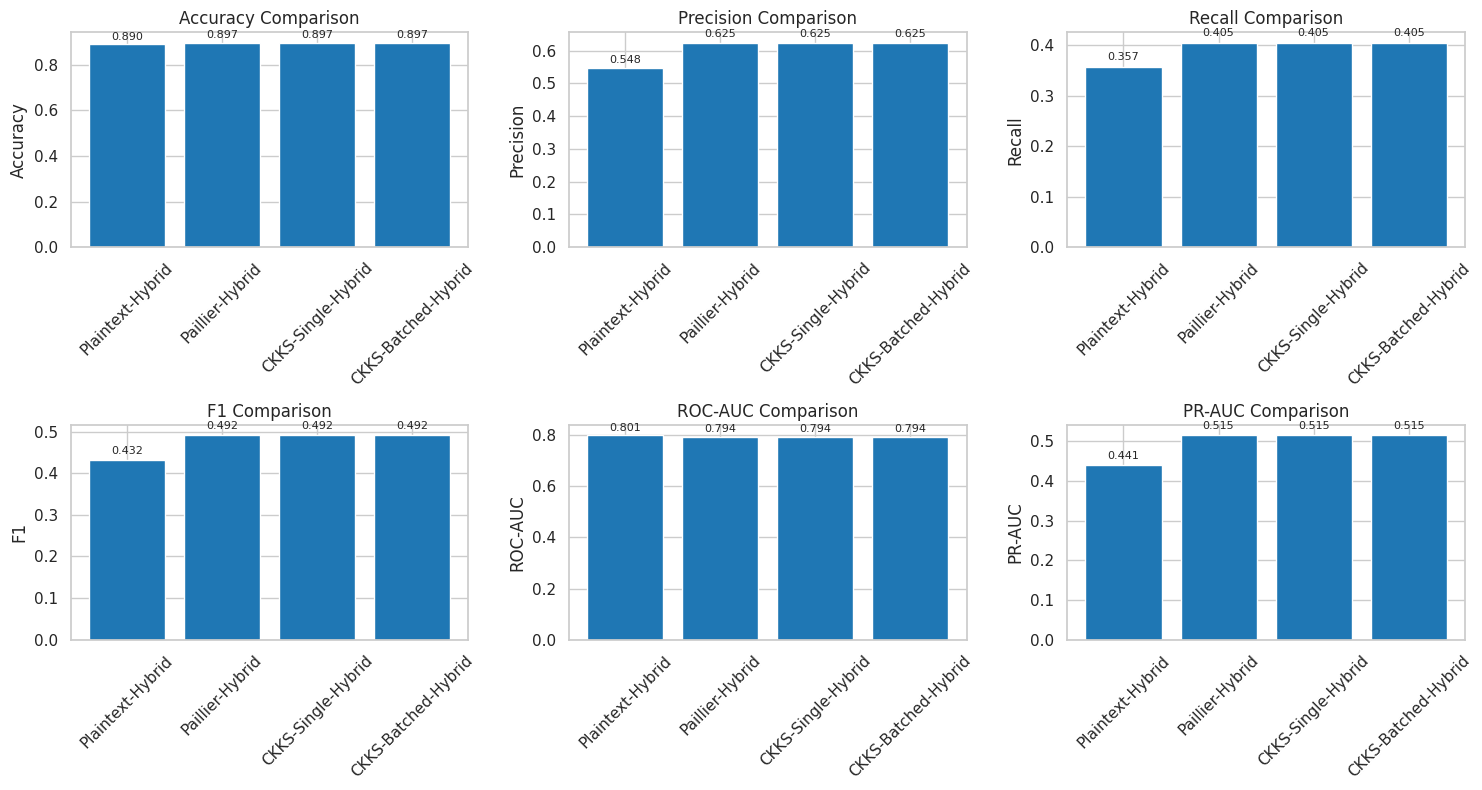

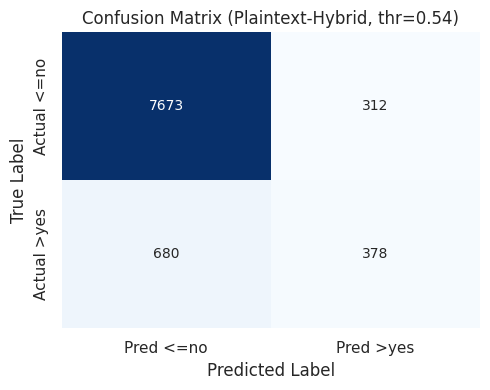

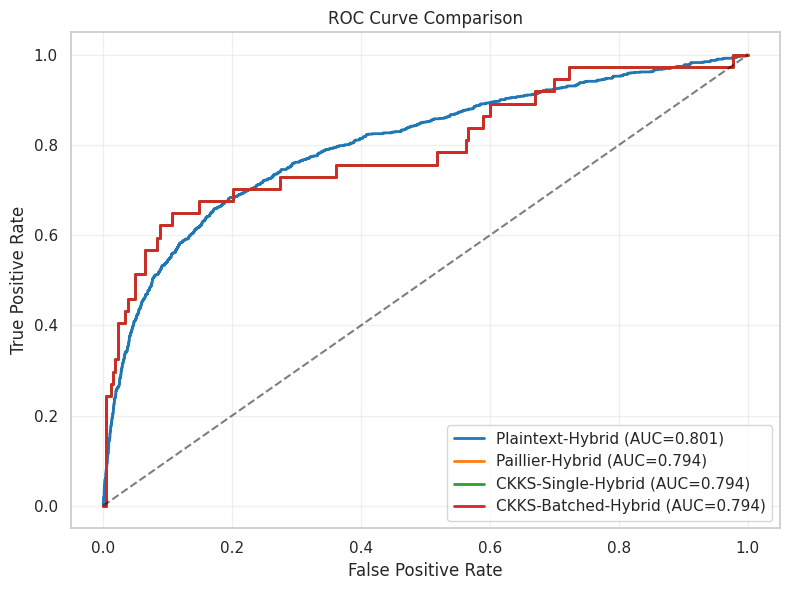

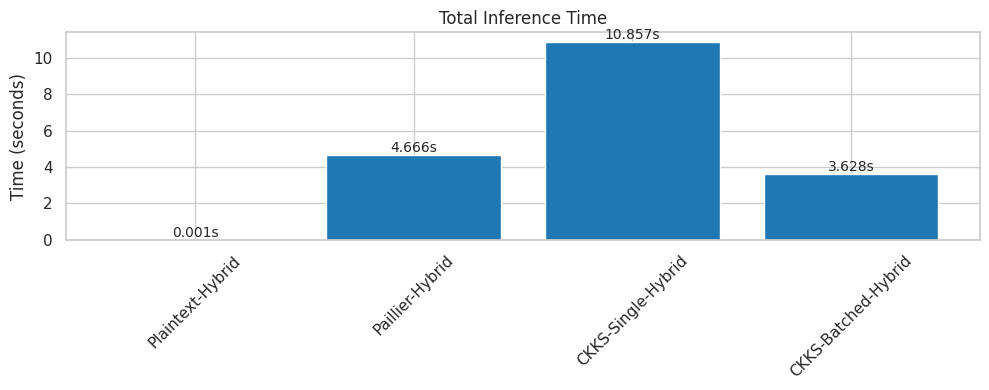


=== Timing Results ===
Plaintext-Hybrid: 0.001s
Paillier-Hybrid: 4.666s (15.6ms per sample)
CKKS-Single-Hybrid: 10.857s (36.2ms per sample)
CKKS-Batched-Hybrid: 3.628s (12.1ms per sample)

Best parameters: {'C': 0.1}, Tuned threshold: 0.540
Number of hybrid features: 18


In [ ]:
# =============================================================================
# Colab-Ready: XGBoost+MLP Hybrid with Homomorphic Encryption
# =============================================================================
# Dataset: Bank Marketing (UCI) – provided as /mnt/data/bank-full.csv
# Modes: Plaintext, Paillier, CKKS-Single, CKKS-Batched
# =============================================================================

# Install required packages (run once in Colab)
!pip install -q tenseal phe imbalanced-learn xgboost tensorflow matplotlib seaborn

import time
import tenseal as ts
import phe as paillier
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import psutil
import gc

from math import isfinite

warnings.filterwarnings('ignore')

# sklearn & imblearn
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, roc_auc_score, average_precision_score,
    precision_score, recall_score, f1_score, confusion_matrix,
    roc_curve, log_loss, brier_score_loss
)
from sklearn.feature_selection import SelectKBest, f_classif
from imblearn.over_sampling import SMOTE

# xgboost & tensorflow
import xgboost as xgb
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam

# reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

# Memory monitoring
def monitor_memory():
    process = psutil.Process()
    memory_info = process.memory_info()
    return memory_info.rss / 1024 ** 2  # MB

# ========================================
# 1) Data loading & preprocessing (Bank Marketing)
# ========================================
print("Loading and preprocessing data...")

# Path: change if necessary; expects bank-full.csv uploaded to /mnt/data/
df = pd.read_csv("/content/bank-full.csv", sep=";")

# target
y = df['y'].apply(lambda x: 1 if str(x).strip().lower() == 'yes' else 0)
df = df.drop(columns=['y'])

# Basic feature engineering
df['age_binned'] = pd.cut(df['age'], bins=5, labels=False)
df['balance_binned'] = pd.cut(df['balance'].replace([np.inf, -np.inf], np.nan).fillna(0), bins=5, labels=False)
df['duration_binned'] = pd.cut(df['duration'].replace([np.inf, -np.inf], np.nan).fillna(0), bins=5, labels=False)

# duration is usually leakage for campaign success; drop to avoid target leakage
if 'duration' in df.columns:
    df = df.drop(columns=['duration'])

# One-hot encode categorical variables (drop_first for memory)
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
df = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

# Feature selection - keep top 30 features
selector = SelectKBest(score_func=f_classif, k=min(30, df.shape[1]))
X_selected = selector.fit_transform(df, y)
selected_mask = selector.get_support()
selected_features = df.columns[selected_mask]
X = pd.DataFrame(X_selected, columns=selected_features)

# cleanup
del df
gc.collect()

# Train/val/test split (stratified)
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.2, random_state=RANDOM_STATE, stratify=y_train_full
)

# Scale (fit on train only)
scaler = StandardScaler(with_mean=True, with_std=True)
X_train_s = scaler.fit_transform(X_train)
X_val_s   = scaler.transform(X_val)
X_test_s  = scaler.transform(X_test)

# Balance classes on train only
sm = SMOTE(random_state=RANDOM_STATE, k_neighbors=5)
X_train_bal, y_train_bal = sm.fit_resample(X_train_s, y_train)

del X_train, X_val
gc.collect()

print(f"Shapes -> X_train_bal: {X_train_bal.shape}, X_val_s: {X_val_s.shape}, X_test_s: {X_test_s.shape}")

# ========================================
# 2) Hybrid XGBoost + MLP Model Training
# ========================================
print("Training Hybrid XGBoost + MLP Feature Extractor...")

# XGBoost feature extractor
xgb_model = xgb.XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    reg_alpha=0.1,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    use_label_encoder=False,
    eval_metric='logloss'
)

xgb_model.fit(X_train_bal, y_train_bal)
X_train_xgb = xgb_model.predict_proba(X_train_bal)
X_val_xgb = xgb_model.predict_proba(X_val_s)

# MLP feature extractor (small for memory)
input_dim = X_train_bal.shape[1]
hidden_units = 32

input_layer = Input(shape=(input_dim,))
hidden1 = Dense(hidden_units, activation='relu')(input_layer)
hidden2 = Dense(hidden_units // 2, activation='relu')(hidden1)
output_layer = Dense(1, activation='sigmoid')(hidden2)

mlp_model = Model(inputs=input_layer, outputs=output_layer)
mlp_model.compile(optimizer=Adam(learning_rate=0.001),
                  loss='binary_crossentropy',
                  metrics=['accuracy'])

mlp_model.fit(X_train_bal, y_train_bal,
              epochs=30, batch_size=64,
              validation_data=(X_val_s, y_val),
              verbose=0)

feature_extractor = Model(inputs=mlp_model.input, outputs=hidden2)
X_train_mlp = feature_extractor.predict(X_train_bal, verbose=0)
X_val_mlp = feature_extractor.predict(X_val_s, verbose=0)

# Combine features
X_train_hybrid = np.hstack((X_train_xgb, X_train_mlp))
X_val_hybrid = np.hstack((X_val_xgb, X_val_mlp))

# Logistic Regression meta-learner with grid search
logreg_hybrid = LogisticRegression(
    penalty="l2", solver="saga", max_iter=2000, class_weight="balanced",
    n_jobs=-1, random_state=RANDOM_STATE, tol=1e-4
)

param_grid = {'C': [0.01, 0.1, 1.0, 10.0]}
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

gs_hybrid = GridSearchCV(
    estimator=logreg_hybrid,
    param_grid=param_grid,
    scoring="average_precision",
    cv=cv,
    n_jobs=-1,
    verbose=0
)
gs_hybrid.fit(X_train_hybrid, y_train_bal)

print(f"Best parameters: {gs_hybrid.best_params_}, Best score: {gs_hybrid.best_score_:.4f}")

# Threshold tuning on validation to maximize F1
val_scores_hybrid = gs_hybrid.best_estimator_.predict_proba(X_val_hybrid)[:, 1]
thresholds = np.linspace(0.2, 0.8, 61)
best_thr, best_f1 = 0.5, -1
for t in thresholds:
    preds = (val_scores_hybrid >= t).astype(int)
    f1 = f1_score(y_val, preds, zero_division=0)
    if f1 > best_f1:
        best_f1, best_thr = f1, t
print(f"Optimal threshold: {best_thr:.3f} (F1: {best_f1:.4f})")

# Retrain on full train (train+val)
X_train_full_s = scaler.fit_transform(X_train_full)
X_train_full_bal, y_train_full_bal = sm.fit_resample(X_train_full_s, y_train_full)

# Extract features for full training data using previously trained extractors
X_train_full_xgb = xgb_model.predict_proba(X_train_full_bal)
X_train_full_mlp = feature_extractor.predict(X_train_full_bal, verbose=0)
X_train_full_hybrid = np.hstack((X_train_full_xgb, X_train_full_mlp))

best_model_final = LogisticRegression(
    penalty="l2", solver="saga", max_iter=2000, class_weight="balanced",
    n_jobs=-1, random_state=RANDOM_STATE, **gs_hybrid.best_params_
)
best_model_final.fit(X_train_full_hybrid, y_train_full_bal)

weights = best_model_final.coef_[0].astype(float)
bias = float(best_model_final.intercept_[0])

# cleanup
del X_train_bal, y_train_bal, X_train_full_bal, y_train_full_bal, X_train_full_s
gc.collect()

# ========================================
# Helpers (evaluation, sigmoid)
# ========================================
def evaluate_model(y_true, y_pred, y_score, label):
    acc   = accuracy_score(y_true, y_pred)
    prec  = precision_score(y_true, y_pred, zero_division=0)
    rec   = recall_score(y_true, y_pred, zero_division=0)
    f1    = f1_score(y_true, y_pred, zero_division=0)
    rocau = roc_auc_score(y_true, y_score) if len(np.unique(y_true)) > 1 else np.nan
    prauc = average_precision_score(y_true, y_score) if len(np.unique(y_true)) > 1 else np.nan
    ll    = log_loss(y_true, np.clip(y_score, 1e-12, 1-1e-12))
    bs    = brier_score_loss(y_true, np.clip(y_score, 1e-12, 1-1e-12))
    return {
        "Mode": label, "Accuracy": acc, "Precision": prec, "Recall": rec, "F1": f1,
        "ROC-AUC": rocau, "PR-AUC": prauc, "LogLoss": ll, "Brier": bs
    }

def sigmoid(x):
    x = np.clip(x, -500, 500)
    return 1.0 / (1.0 + np.exp(-x))

results = []

# ========================================
# 3) Plaintext Inference (with tuned threshold)
# ========================================
print("\n=== Plaintext Inference ===")
X_test_xgb = xgb_model.predict_proba(X_test_s)
X_test_mlp = feature_extractor.predict(X_test_s, verbose=0)
X_test_hybrid = np.hstack((X_test_xgb, X_test_mlp))

start = time.time()
logits = np.dot(X_test_hybrid, weights) + bias
plaintext_probs = sigmoid(logits)
plaintext_preds = (plaintext_probs >= best_thr).astype(int)
plaintext_time = time.time() - start

results.append(evaluate_model(y_test.to_numpy(), plaintext_preds, plaintext_probs, "Plaintext-Hybrid"))
print(f"[Plaintext-Hybrid] inference in {plaintext_time:.3f}s | tuned threshold = {best_thr:.3f}")

del logits
gc.collect()

# ========================================
# 4) Paillier Homomorphic Encryption
# ========================================
print("\n=== Paillier Homomorphic Encryption ===")
# Use 1024-bit for speed in Colab experiments (weaker than 2048)
pk, sk = paillier.generate_paillier_keypair(n_length=1024)

# Encrypt weights and bias (as floats)
enc_weights = [pk.encrypt(float(w)) for w in weights]
enc_bias = pk.encrypt(float(bias))

# Reduced sample size for memory
fixed_sample_size = 300
sample_size = min(fixed_sample_size, X_test_hybrid.shape[0])
X_sample_hybrid = X_test_hybrid[:sample_size]
y_sample = y_test.to_numpy()[:sample_size]

start = time.time()
enc_logits = []
for xi in X_sample_hybrid:
    dot = enc_bias
    # dot with encrypted weights: enc(w)*x + bias
    for xij, enc_wj in zip(xi, enc_weights):
        dot = dot + enc_wj * float(xij)
    enc_logits.append(dot)

# decrypt
decrypted_logits = np.array([sk.decrypt(val) for val in enc_logits], dtype=float)
decrypted_logits[~np.isfinite(decrypted_logits)] = 0.0
paillier_probs = sigmoid(decrypted_logits)
paillier_preds = (paillier_probs >= best_thr).astype(int)
paillier_time = time.time() - start

results.append(evaluate_model(y_sample, paillier_preds, paillier_probs, "Paillier-Hybrid"))
print(f"[Paillier-Hybrid] inference ({sample_size} samples) in {paillier_time:.3f}s")

del enc_weights, enc_bias, enc_logits, decrypted_logits
gc.collect()

# ========================================
# 5) CKKS Homomorphic Encryption (Single-sample)
# ========================================
print("\n=== CKKS Homomorphic Encryption (Single-sample) ===")

def build_ckks_context(poly_mod=8192, coeff_mod_bit_sizes=[60, 40, 40, 60], scale=2**40):
    ctx = ts.context(ts.SCHEME_TYPE.CKKS, poly_mod, -1, coeff_mod_bit_sizes)
    ctx.generate_galois_keys()
    ctx.global_scale = scale
    return ctx

ckks_single_time = float('nan')
try:
    context = build_ckks_context()

    enc_weights_ckks = ts.ckks_vector(context, weights.tolist())
    enc_bias_ckks = ts.ckks_vector(context, [bias])

    start = time.time()
    enc_logits_ckks = []
    for xi in X_sample_hybrid:
        enc_xi = ts.ckks_vector(context, xi.tolist())
        dot_product = enc_xi.dot(enc_weights_ckks)
        encrypted_logit = dot_product + enc_bias_ckks
        enc_logits_ckks.append(encrypted_logit)

    # decrypt each
    decrypted_logits_ckks = np.array([vec.decrypt()[0] for vec in enc_logits_ckks], dtype=float)
    ckks_single_probs = sigmoid(decrypted_logits_ckks)
    ckks_single_preds = (ckks_single_probs >= best_thr).astype(int)
    ckks_single_time = time.time() - start

    results.append(evaluate_model(y_sample, ckks_single_preds, ckks_single_probs, "CKKS-Single-Hybrid"))
    print(f"[CKKS-Single-Hybrid] inference ({sample_size} samples) in {ckks_single_time:.3f}s")

except Exception as e:
    print(f"CKKS-Single failed: {e}")
    results.append({
        "Mode": "CKKS-Single-Hybrid", "Accuracy": np.nan, "Precision": np.nan,
        "Recall": np.nan, "F1": np.nan, "ROC-AUC": np.nan, "PR-AUC": np.nan, "LogLoss": np.nan, "Brier": np.nan
    })

# cleanup ckks single vars if present
ckks_vars = ['context', 'enc_weights_ckks', 'enc_bias_ckks', 'enc_logits_ckks', 'decrypted_logits_ckks']
for var in ckks_vars:
    if var in locals():
        del locals()[var]
gc.collect()

print(f"Memory after CKKS-Single: {monitor_memory():.2f} MB")

# ========================================
# 6) CKKS Homomorphic Encryption (Batched)
# ========================================
print("\n=== CKKS Homomorphic Encryption (Batched) ===")

ckks_batch_time = float('nan')
try:
    context = build_ckks_context()
    batch_size = min(16, sample_size)
    num_batches = int(np.ceil(sample_size / batch_size))

    start = time.time()
    decrypted_logits_batch = []

    for b in range(num_batches):
        batch_start = b * batch_size
        batch_end = min((b + 1) * batch_size, sample_size)
        current_bs = batch_end - batch_start
        batch_samples = X_sample_hybrid[batch_start:batch_end]

        weighted_sum = None
        for j in range(batch_samples.shape[1]):
            col_data = batch_samples[:, j].astype(float).tolist()
            enc_col = ts.ckks_vector(context, col_data)
            weighted_col = enc_col * float(weights[j])
            weighted_sum = weighted_col if weighted_sum is None else (weighted_sum + weighted_col)

        batch_bias = ts.ckks_vector(context, [float(bias)] * current_bs)
        encrypted_logits_batch = weighted_sum + batch_bias

        decrypted_logits_batch.extend(encrypted_logits_batch.decrypt())

    decrypted_logits_batch = np.array(decrypted_logits_batch, dtype=float)
    ckks_batch_probs = sigmoid(decrypted_logits_batch)
    ckks_batch_preds = (ckks_batch_probs >= best_thr).astype(int)
    ckks_batch_time = time.time() - start

    results.append(evaluate_model(y_sample[:len(ckks_batch_preds)], ckks_batch_preds, ckks_batch_probs, "CKKS-Batched-Hybrid"))
    print(f"[CKKS-Batched-Hybrid] inference ({len(ckks_batch_preds)} samples) in {ckks_batch_time:.3f}s")

except Exception as e:
    print(f"CKKS-Batched failed: {e}")
    results.append({
        "Mode": "CKKS-Batched-Hybrid", "Accuracy": np.nan, "Precision": np.nan,
        "Recall": np.nan, "F1": np.nan, "ROC-AUC": np.nan, "PR-AUC": np.nan, "LogLoss": np.nan, "Brier": np.nan
    })

# cleanup ckks batch vars if present
ckks_batch_vars = ['context', 'weighted_sum', 'batch_bias', 'encrypted_logits_batch', 'decrypted_logits_batch']
for var in ckks_batch_vars:
    if var in locals():
        del locals()[var]
gc.collect()

print(f"Memory after CKKS-Batched: {monitor_memory():.2f} MB")

# ========================================
# 7) Results Analysis & Plots
# ========================================
df_results = pd.DataFrame(results)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1500)
print("\n=== Evaluation Results ===")
print(df_results.round(4))

# Degradation vs plaintext
if 'Plaintext-Hybrid' in df_results['Mode'].values:
    plaintext_metrics = df_results[df_results['Mode'] == 'Plaintext-Hybrid'].iloc[0]
    degradation = []
    for _, row in df_results.iterrows():
        if row['Mode'] != 'Plaintext-Hybrid' and not np.isnan(row['Accuracy']):
            deg = {
                'Mode': row['Mode'],
                'Accuracy_Degradation': (plaintext_metrics['Accuracy'] - row['Accuracy']) / plaintext_metrics['Accuracy'] * 100 if plaintext_metrics['Accuracy'] != 0 else np.nan,
                'F1_Degradation': (plaintext_metrics['F1'] - row['F1']) / plaintext_metrics['F1'] * 100 if plaintext_metrics['F1'] != 0 else np.nan,
            }
            degradation.append(deg)

    if degradation:
        df_degradation = pd.DataFrame(degradation)
        print("\n=== Performance Degradation vs Plaintext (%) ===")
        print(df_degradation.round(2))
    else:
        print("\nNo encrypted models produced valid results for degradation comparison")
else:
    print("\nPlaintext results missing - skipping degradation calculation")

# Simple visualizations (kept small for Colab)
sns.set_context("notebook")
sns.set_style("whitegrid")
plt.rcParams['font.size'] = 10

# Metrics plotting (only existing numeric metrics)
metrics = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC']
present_metrics = [m for m in metrics if m in df_results.columns]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()
for i, metric in enumerate(present_metrics):
    vals = df_results[metric].fillna(0).values
    bars = axes[i].bar(df_results['Mode'], vals)
    axes[i].set_title(f'{metric} Comparison')
    axes[i].set_ylabel(metric)
    axes[i].tick_params(axis='x', rotation=45)
    for bar in bars:
        h = bar.get_height()
        axes[i].text(bar.get_x() + bar.get_width() / 2., h + 0.01, f'{h:.3f}', ha='center', va='bottom', fontsize=8)

# hide unused subplots
for j in range(len(present_metrics), 6):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

# Confusion matrix for Plaintext
if 'Plaintext-Hybrid' in df_results['Mode'].values:
    cm = confusion_matrix(y_test.to_numpy(), plaintext_preds)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=['Pred <=no', 'Pred >yes'],
                yticklabels=['Actual <=no', 'Actual >yes'])
    plt.title(f"Confusion Matrix (Plaintext-Hybrid, thr={best_thr:.2f})")
    plt.ylabel("True Label")
    plt.xlabel("Predicted Label")
    plt.tight_layout()
    plt.show()

# ROC curves
plt.figure(figsize=(8, 6))
if len(np.unique(y_test)) > 1:
    try:
        fpr, tpr, _ = roc_curve(y_test.to_numpy(), plaintext_probs)
        auc_plain = roc_auc_score(y_test.to_numpy(), plaintext_probs)
        plt.plot(fpr, tpr, label=f'Plaintext-Hybrid (AUC={auc_plain:.3f})', linewidth=2)
    except Exception:
        pass

if 'Paillier-Hybrid' in df_results['Mode'].values and not np.isnan(df_results[df_results['Mode'] == 'Paillier-Hybrid']['ROC-AUC'].values[0]):
    try:
        fpr_p, tpr_p, _ = roc_curve(y_sample, paillier_probs)
        plt.plot(fpr_p, tpr_p, label=f'Paillier-Hybrid (AUC={roc_auc_score(y_sample, paillier_probs):.3f})', linewidth=2)
    except Exception:
        pass

if 'CKKS-Single-Hybrid' in df_results['Mode'].values and 'ckks_single_probs' in locals():
    try:
        fpr_cs, tpr_cs, _ = roc_curve(y_sample, ckks_single_probs)
        plt.plot(fpr_cs, tpr_cs, label=f'CKKS-Single-Hybrid (AUC={roc_auc_score(y_sample, ckks_single_probs):.3f})', linewidth=2)
    except Exception:
        pass

if 'CKKS-Batched-Hybrid' in df_results['Mode'].values and 'ckks_batch_probs' in locals():
    try:
        fpr_cb, tpr_cb, _ = roc_curve(y_sample[:len(ckks_batch_probs)], ckks_batch_probs)
        plt.plot(fpr_cb, tpr_cb, label=f'CKKS-Batched-Hybrid (AUC={roc_auc_score(y_sample[:len(ckks_batch_probs)], ckks_batch_probs):.3f})', linewidth=2)
    except Exception:
        pass

plt.plot([0, 1], [0, 1], 'k--', alpha=0.5)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Timing comparison
timing_data = {
    'Method': ['Plaintext-Hybrid', 'Paillier-Hybrid', 'CKKS-Single-Hybrid', 'CKKS-Batched-Hybrid'],
    'Time (s)': [float(plaintext_time), float(paillier_time),
                float(ckks_single_time) if not np.isnan(ckks_single_time) else 0,
                float(ckks_batch_time) if not np.isnan(ckks_batch_time) else 0]
}

timing_data['Time per sample (ms)'] = [0] * len(timing_data['Method'])
for i, method in enumerate(timing_data['Method']):
    if method != 'Plaintext-Hybrid' and sample_size > 0:
        timing_data['Time per sample (ms)'][i] = timing_data['Time (s)'][i] / sample_size * 1000

plt.figure(figsize=(10, 4))
bars = plt.bar(timing_data['Method'], timing_data['Time (s)'])
plt.title('Total Inference Time')
plt.ylabel('Time (seconds)')
plt.xticks(rotation=45)
for bar in bars:
    height = bar.get_height()
    if height > 0:
        plt.text(bar.get_x() + bar.get_width()/2., height + 0.01, f'{height:.3f}s', ha='center', va='bottom')
plt.tight_layout()
plt.show()

print("\n=== Timing Results ===")
for i, m in enumerate(timing_data['Method']):
    if m == 'Plaintext-Hybrid':
        print(f"{m}: {timing_data['Time (s)'][i]:.3f}s")
    else:
        print(f"{m}: {timing_data['Time (s)'][i]:.3f}s ({timing_data['Time per sample (ms)'][i]:.1f}ms per sample)")

print(f"\nBest parameters: {gs_hybrid.best_params_}, Tuned threshold: {best_thr:.3f}")
print(f"Number of hybrid features: {len(weights)}")




# **Bank Full 500 Samples**

Loading and preprocessing data...
Shapes -> X_train_bal: (51098, 30), X_val_s: (7234, 30), X_test_s: (9043, 30)
Training Hybrid XGBoost + MLP Feature Extractor...
Best parameters: {'C': 0.1}, Best score: 0.9800
Optimal threshold: 0.490 (F1: 0.4968)

=== Plaintext Inference ===
[Plaintext-Hybrid] inference in 0.001s | tuned threshold = 0.490

=== Paillier Homomorphic Encryption ===
[Paillier-Hybrid] inference (500 samples) in 8.560s

=== CKKS Homomorphic Encryption (Single-sample) ===
[CKKS-Single-Hybrid] inference (500 samples) in 19.061s
Memory after CKKS-Single: 1367.95 MB

=== CKKS Homomorphic Encryption (Batched) ===
[CKKS-Batched-Hybrid] inference (500 samples) in 5.960s
Memory after CKKS-Batched: 1367.95 MB

=== Evaluation Results ===
                  Mode  Accuracy  Precision  Recall      F1  ROC-AUC  PR-AUC  LogLoss   Brier
0     Plaintext-Hybrid    0.8901     0.5429  0.3828  0.4490   0.7989  0.4290   0.3155  0.0872
1      Paillier-Hybrid    0.9060     0.5833  0.5091  0.5437  

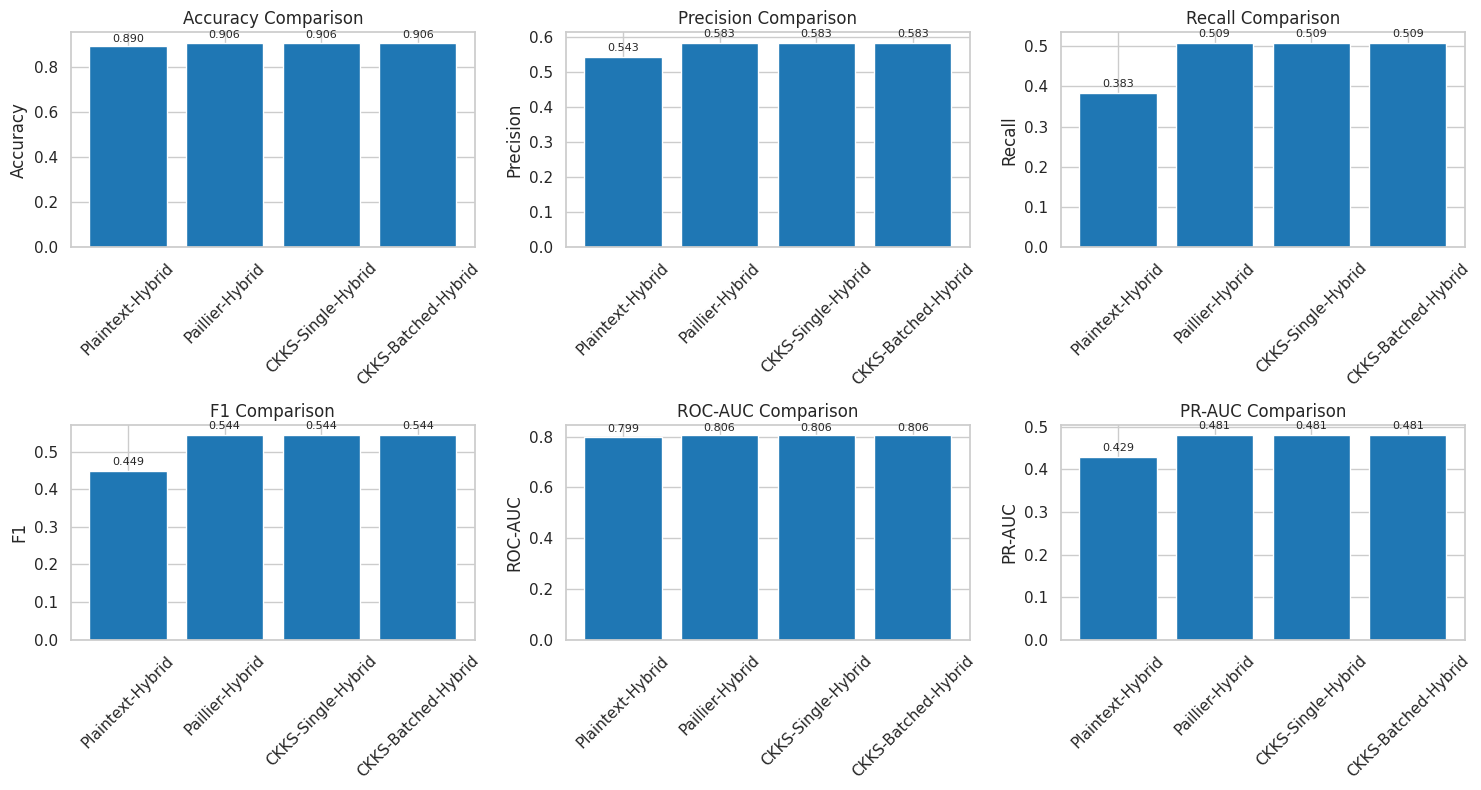

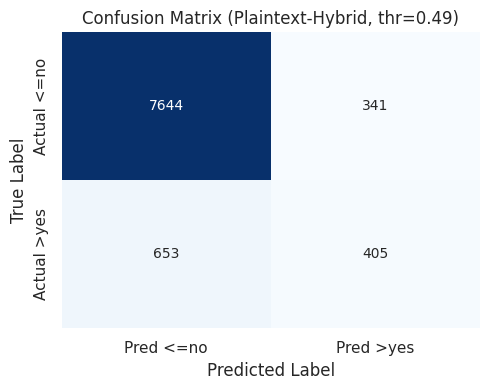

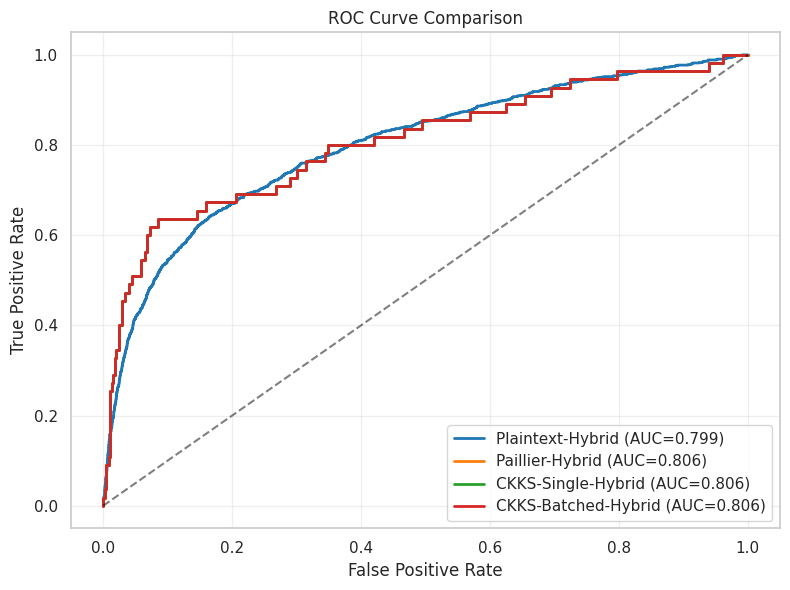

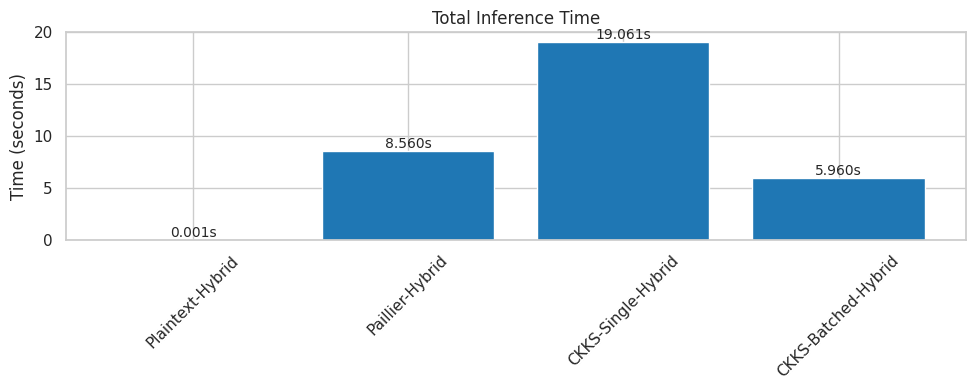


=== Timing Results ===
Plaintext-Hybrid: 0.001s
Paillier-Hybrid: 8.560s (17.1ms per sample)
CKKS-Single-Hybrid: 19.061s (38.1ms per sample)
CKKS-Batched-Hybrid: 5.960s (11.9ms per sample)

Best parameters: {'C': 0.1}, Tuned threshold: 0.490
Number of hybrid features: 18


In [ ]:
# =============================================================================
# Colab-Ready: XGBoost+MLP Hybrid with Homomorphic Encryption
# =============================================================================
# Dataset: Bank Marketing (UCI) – provided as /mnt/data/bank-full.csv
# Modes: Plaintext, Paillier, CKKS-Single, CKKS-Batched
# =============================================================================

# Install required packages (run once in Colab)
!pip install -q tenseal phe imbalanced-learn xgboost tensorflow matplotlib seaborn

import time
import tenseal as ts
import phe as paillier
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import psutil
import gc

from math import isfinite

warnings.filterwarnings('ignore')

# sklearn & imblearn
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, roc_auc_score, average_precision_score,
    precision_score, recall_score, f1_score, confusion_matrix,
    roc_curve, log_loss, brier_score_loss
)
from sklearn.feature_selection import SelectKBest, f_classif
from imblearn.over_sampling import SMOTE

# xgboost & tensorflow
import xgboost as xgb
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam

# reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

# Memory monitoring
def monitor_memory():
    process = psutil.Process()
    memory_info = process.memory_info()
    return memory_info.rss / 1024 ** 2  # MB

# ========================================
# 1) Data loading & preprocessing (Bank Marketing)
# ========================================
print("Loading and preprocessing data...")

# Path: change if necessary; expects bank-full.csv uploaded to /mnt/data/
df = pd.read_csv("/content/bank-full.csv", sep=";")

# target
y = df['y'].apply(lambda x: 1 if str(x).strip().lower() == 'yes' else 0)
df = df.drop(columns=['y'])

# Basic feature engineering
df['age_binned'] = pd.cut(df['age'], bins=5, labels=False)
df['balance_binned'] = pd.cut(df['balance'].replace([np.inf, -np.inf], np.nan).fillna(0), bins=5, labels=False)
df['duration_binned'] = pd.cut(df['duration'].replace([np.inf, -np.inf], np.nan).fillna(0), bins=5, labels=False)

# duration is usually leakage for campaign success; drop to avoid target leakage
if 'duration' in df.columns:
    df = df.drop(columns=['duration'])

# One-hot encode categorical variables (drop_first for memory)
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
df = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

# Feature selection - keep top 30 features
selector = SelectKBest(score_func=f_classif, k=min(30, df.shape[1]))
X_selected = selector.fit_transform(df, y)
selected_mask = selector.get_support()
selected_features = df.columns[selected_mask]
X = pd.DataFrame(X_selected, columns=selected_features)

# cleanup
del df
gc.collect()

# Train/val/test split (stratified)
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.2, random_state=RANDOM_STATE, stratify=y_train_full
)

# Scale (fit on train only)
scaler = StandardScaler(with_mean=True, with_std=True)
X_train_s = scaler.fit_transform(X_train)
X_val_s   = scaler.transform(X_val)
X_test_s  = scaler.transform(X_test)

# Balance classes on train only
sm = SMOTE(random_state=RANDOM_STATE, k_neighbors=5)
X_train_bal, y_train_bal = sm.fit_resample(X_train_s, y_train)

del X_train, X_val
gc.collect()

print(f"Shapes -> X_train_bal: {X_train_bal.shape}, X_val_s: {X_val_s.shape}, X_test_s: {X_test_s.shape}")

# ========================================
# 2) Hybrid XGBoost + MLP Model Training
# ========================================
print("Training Hybrid XGBoost + MLP Feature Extractor...")

# XGBoost feature extractor
xgb_model = xgb.XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    reg_alpha=0.1,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    use_label_encoder=False,
    eval_metric='logloss'
)

xgb_model.fit(X_train_bal, y_train_bal)
X_train_xgb = xgb_model.predict_proba(X_train_bal)
X_val_xgb = xgb_model.predict_proba(X_val_s)

# MLP feature extractor (small for memory)
input_dim = X_train_bal.shape[1]
hidden_units = 32

input_layer = Input(shape=(input_dim,))
hidden1 = Dense(hidden_units, activation='relu')(input_layer)
hidden2 = Dense(hidden_units // 2, activation='relu')(hidden1)
output_layer = Dense(1, activation='sigmoid')(hidden2)

mlp_model = Model(inputs=input_layer, outputs=output_layer)
mlp_model.compile(optimizer=Adam(learning_rate=0.001),
                  loss='binary_crossentropy',
                  metrics=['accuracy'])

mlp_model.fit(X_train_bal, y_train_bal,
              epochs=30, batch_size=64,
              validation_data=(X_val_s, y_val),
              verbose=0)

feature_extractor = Model(inputs=mlp_model.input, outputs=hidden2)
X_train_mlp = feature_extractor.predict(X_train_bal, verbose=0)
X_val_mlp = feature_extractor.predict(X_val_s, verbose=0)

# Combine features
X_train_hybrid = np.hstack((X_train_xgb, X_train_mlp))
X_val_hybrid = np.hstack((X_val_xgb, X_val_mlp))

# Logistic Regression meta-learner with grid search
logreg_hybrid = LogisticRegression(
    penalty="l2", solver="saga", max_iter=2000, class_weight="balanced",
    n_jobs=-1, random_state=RANDOM_STATE, tol=1e-4
)

param_grid = {'C': [0.01, 0.1, 1.0, 10.0]}
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

gs_hybrid = GridSearchCV(
    estimator=logreg_hybrid,
    param_grid=param_grid,
    scoring="average_precision",
    cv=cv,
    n_jobs=-1,
    verbose=0
)
gs_hybrid.fit(X_train_hybrid, y_train_bal)

print(f"Best parameters: {gs_hybrid.best_params_}, Best score: {gs_hybrid.best_score_:.4f}")

# Threshold tuning on validation to maximize F1
val_scores_hybrid = gs_hybrid.best_estimator_.predict_proba(X_val_hybrid)[:, 1]
thresholds = np.linspace(0.2, 0.8, 61)
best_thr, best_f1 = 0.5, -1
for t in thresholds:
    preds = (val_scores_hybrid >= t).astype(int)
    f1 = f1_score(y_val, preds, zero_division=0)
    if f1 > best_f1:
        best_f1, best_thr = f1, t
print(f"Optimal threshold: {best_thr:.3f} (F1: {best_f1:.4f})")

# Retrain on full train (train+val)
X_train_full_s = scaler.fit_transform(X_train_full)
X_train_full_bal, y_train_full_bal = sm.fit_resample(X_train_full_s, y_train_full)

# Extract features for full training data using previously trained extractors
X_train_full_xgb = xgb_model.predict_proba(X_train_full_bal)
X_train_full_mlp = feature_extractor.predict(X_train_full_bal, verbose=0)
X_train_full_hybrid = np.hstack((X_train_full_xgb, X_train_full_mlp))

best_model_final = LogisticRegression(
    penalty="l2", solver="saga", max_iter=2000, class_weight="balanced",
    n_jobs=-1, random_state=RANDOM_STATE, **gs_hybrid.best_params_
)
best_model_final.fit(X_train_full_hybrid, y_train_full_bal)

weights = best_model_final.coef_[0].astype(float)
bias = float(best_model_final.intercept_[0])

# cleanup
del X_train_bal, y_train_bal, X_train_full_bal, y_train_full_bal, X_train_full_s
gc.collect()

# ========================================
# Helpers (evaluation, sigmoid)
# ========================================
def evaluate_model(y_true, y_pred, y_score, label):
    acc   = accuracy_score(y_true, y_pred)
    prec  = precision_score(y_true, y_pred, zero_division=0)
    rec   = recall_score(y_true, y_pred, zero_division=0)
    f1    = f1_score(y_true, y_pred, zero_division=0)
    rocau = roc_auc_score(y_true, y_score) if len(np.unique(y_true)) > 1 else np.nan
    prauc = average_precision_score(y_true, y_score) if len(np.unique(y_true)) > 1 else np.nan
    ll    = log_loss(y_true, np.clip(y_score, 1e-12, 1-1e-12))
    bs    = brier_score_loss(y_true, np.clip(y_score, 1e-12, 1-1e-12))
    return {
        "Mode": label, "Accuracy": acc, "Precision": prec, "Recall": rec, "F1": f1,
        "ROC-AUC": rocau, "PR-AUC": prauc, "LogLoss": ll, "Brier": bs
    }

def sigmoid(x):
    x = np.clip(x, -500, 500)
    return 1.0 / (1.0 + np.exp(-x))

results = []

# ========================================
# 3) Plaintext Inference (with tuned threshold)
# ========================================
print("\n=== Plaintext Inference ===")
X_test_xgb = xgb_model.predict_proba(X_test_s)
X_test_mlp = feature_extractor.predict(X_test_s, verbose=0)
X_test_hybrid = np.hstack((X_test_xgb, X_test_mlp))

start = time.time()
logits = np.dot(X_test_hybrid, weights) + bias
plaintext_probs = sigmoid(logits)
plaintext_preds = (plaintext_probs >= best_thr).astype(int)
plaintext_time = time.time() - start

results.append(evaluate_model(y_test.to_numpy(), plaintext_preds, plaintext_probs, "Plaintext-Hybrid"))
print(f"[Plaintext-Hybrid] inference in {plaintext_time:.3f}s | tuned threshold = {best_thr:.3f}")

del logits
gc.collect()

# ========================================
# 4) Paillier Homomorphic Encryption
# ========================================
print("\n=== Paillier Homomorphic Encryption ===")
# Use 1024-bit for speed in Colab experiments (weaker than 2048)
pk, sk = paillier.generate_paillier_keypair(n_length=1024)

# Encrypt weights and bias (as floats)
enc_weights = [pk.encrypt(float(w)) for w in weights]
enc_bias = pk.encrypt(float(bias))

# Reduced sample size for memory
fixed_sample_size = 500
sample_size = min(fixed_sample_size, X_test_hybrid.shape[0])
X_sample_hybrid = X_test_hybrid[:sample_size]
y_sample = y_test.to_numpy()[:sample_size]

start = time.time()
enc_logits = []
for xi in X_sample_hybrid:
    dot = enc_bias
    # dot with encrypted weights: enc(w)*x + bias
    for xij, enc_wj in zip(xi, enc_weights):
        dot = dot + enc_wj * float(xij)
    enc_logits.append(dot)

# decrypt
decrypted_logits = np.array([sk.decrypt(val) for val in enc_logits], dtype=float)
decrypted_logits[~np.isfinite(decrypted_logits)] = 0.0
paillier_probs = sigmoid(decrypted_logits)
paillier_preds = (paillier_probs >= best_thr).astype(int)
paillier_time = time.time() - start

results.append(evaluate_model(y_sample, paillier_preds, paillier_probs, "Paillier-Hybrid"))
print(f"[Paillier-Hybrid] inference ({sample_size} samples) in {paillier_time:.3f}s")

del enc_weights, enc_bias, enc_logits, decrypted_logits
gc.collect()

# ========================================
# 5) CKKS Homomorphic Encryption (Single-sample)
# ========================================
print("\n=== CKKS Homomorphic Encryption (Single-sample) ===")

def build_ckks_context(poly_mod=8192, coeff_mod_bit_sizes=[60, 40, 40, 60], scale=2**40):
    ctx = ts.context(ts.SCHEME_TYPE.CKKS, poly_mod, -1, coeff_mod_bit_sizes)
    ctx.generate_galois_keys()
    ctx.global_scale = scale
    return ctx

ckks_single_time = float('nan')
try:
    context = build_ckks_context()

    enc_weights_ckks = ts.ckks_vector(context, weights.tolist())
    enc_bias_ckks = ts.ckks_vector(context, [bias])

    start = time.time()
    enc_logits_ckks = []
    for xi in X_sample_hybrid:
        enc_xi = ts.ckks_vector(context, xi.tolist())
        dot_product = enc_xi.dot(enc_weights_ckks)
        encrypted_logit = dot_product + enc_bias_ckks
        enc_logits_ckks.append(encrypted_logit)

    # decrypt each
    decrypted_logits_ckks = np.array([vec.decrypt()[0] for vec in enc_logits_ckks], dtype=float)
    ckks_single_probs = sigmoid(decrypted_logits_ckks)
    ckks_single_preds = (ckks_single_probs >= best_thr).astype(int)
    ckks_single_time = time.time() - start

    results.append(evaluate_model(y_sample, ckks_single_preds, ckks_single_probs, "CKKS-Single-Hybrid"))
    print(f"[CKKS-Single-Hybrid] inference ({sample_size} samples) in {ckks_single_time:.3f}s")

except Exception as e:
    print(f"CKKS-Single failed: {e}")
    results.append({
        "Mode": "CKKS-Single-Hybrid", "Accuracy": np.nan, "Precision": np.nan,
        "Recall": np.nan, "F1": np.nan, "ROC-AUC": np.nan, "PR-AUC": np.nan, "LogLoss": np.nan, "Brier": np.nan
    })

# cleanup ckks single vars if present
ckks_vars = ['context', 'enc_weights_ckks', 'enc_bias_ckks', 'enc_logits_ckks', 'decrypted_logits_ckks']
for var in ckks_vars:
    if var in locals():
        del locals()[var]
gc.collect()

print(f"Memory after CKKS-Single: {monitor_memory():.2f} MB")

# ========================================
# 6) CKKS Homomorphic Encryption (Batched)
# ========================================
print("\n=== CKKS Homomorphic Encryption (Batched) ===")

ckks_batch_time = float('nan')
try:
    context = build_ckks_context()
    batch_size = min(16, sample_size)
    num_batches = int(np.ceil(sample_size / batch_size))

    start = time.time()
    decrypted_logits_batch = []

    for b in range(num_batches):
        batch_start = b * batch_size
        batch_end = min((b + 1) * batch_size, sample_size)
        current_bs = batch_end - batch_start
        batch_samples = X_sample_hybrid[batch_start:batch_end]

        weighted_sum = None
        for j in range(batch_samples.shape[1]):
            col_data = batch_samples[:, j].astype(float).tolist()
            enc_col = ts.ckks_vector(context, col_data)
            weighted_col = enc_col * float(weights[j])
            weighted_sum = weighted_col if weighted_sum is None else (weighted_sum + weighted_col)

        batch_bias = ts.ckks_vector(context, [float(bias)] * current_bs)
        encrypted_logits_batch = weighted_sum + batch_bias

        decrypted_logits_batch.extend(encrypted_logits_batch.decrypt())

    decrypted_logits_batch = np.array(decrypted_logits_batch, dtype=float)
    ckks_batch_probs = sigmoid(decrypted_logits_batch)
    ckks_batch_preds = (ckks_batch_probs >= best_thr).astype(int)
    ckks_batch_time = time.time() - start

    results.append(evaluate_model(y_sample[:len(ckks_batch_preds)], ckks_batch_preds, ckks_batch_probs, "CKKS-Batched-Hybrid"))
    print(f"[CKKS-Batched-Hybrid] inference ({len(ckks_batch_preds)} samples) in {ckks_batch_time:.3f}s")

except Exception as e:
    print(f"CKKS-Batched failed: {e}")
    results.append({
        "Mode": "CKKS-Batched-Hybrid", "Accuracy": np.nan, "Precision": np.nan,
        "Recall": np.nan, "F1": np.nan, "ROC-AUC": np.nan, "PR-AUC": np.nan, "LogLoss": np.nan, "Brier": np.nan
    })

# cleanup ckks batch vars if present
ckks_batch_vars = ['context', 'weighted_sum', 'batch_bias', 'encrypted_logits_batch', 'decrypted_logits_batch']
for var in ckks_batch_vars:
    if var in locals():
        del locals()[var]
gc.collect()

print(f"Memory after CKKS-Batched: {monitor_memory():.2f} MB")

# ========================================
# 7) Results Analysis & Plots
# ========================================
df_results = pd.DataFrame(results)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1500)
print("\n=== Evaluation Results ===")
print(df_results.round(4))

# Degradation vs plaintext
if 'Plaintext-Hybrid' in df_results['Mode'].values:
    plaintext_metrics = df_results[df_results['Mode'] == 'Plaintext-Hybrid'].iloc[0]
    degradation = []
    for _, row in df_results.iterrows():
        if row['Mode'] != 'Plaintext-Hybrid' and not np.isnan(row['Accuracy']):
            deg = {
                'Mode': row['Mode'],
                'Accuracy_Degradation': (plaintext_metrics['Accuracy'] - row['Accuracy']) / plaintext_metrics['Accuracy'] * 100 if plaintext_metrics['Accuracy'] != 0 else np.nan,
                'F1_Degradation': (plaintext_metrics['F1'] - row['F1']) / plaintext_metrics['F1'] * 100 if plaintext_metrics['F1'] != 0 else np.nan,
            }
            degradation.append(deg)

    if degradation:
        df_degradation = pd.DataFrame(degradation)
        print("\n=== Performance Degradation vs Plaintext (%) ===")
        print(df_degradation.round(2))
    else:
        print("\nNo encrypted models produced valid results for degradation comparison")
else:
    print("\nPlaintext results missing - skipping degradation calculation")

# Simple visualizations (kept small for Colab)
sns.set_context("notebook")
sns.set_style("whitegrid")
plt.rcParams['font.size'] = 10

# Metrics plotting (only existing numeric metrics)
metrics = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC']
present_metrics = [m for m in metrics if m in df_results.columns]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()
for i, metric in enumerate(present_metrics):
    vals = df_results[metric].fillna(0).values
    bars = axes[i].bar(df_results['Mode'], vals)
    axes[i].set_title(f'{metric} Comparison')
    axes[i].set_ylabel(metric)
    axes[i].tick_params(axis='x', rotation=45)
    for bar in bars:
        h = bar.get_height()
        axes[i].text(bar.get_x() + bar.get_width() / 2., h + 0.01, f'{h:.3f}', ha='center', va='bottom', fontsize=8)

# hide unused subplots
for j in range(len(present_metrics), 6):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

# Confusion matrix for Plaintext
if 'Plaintext-Hybrid' in df_results['Mode'].values:
    cm = confusion_matrix(y_test.to_numpy(), plaintext_preds)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=['Pred <=no', 'Pred >yes'],
                yticklabels=['Actual <=no', 'Actual >yes'])
    plt.title(f"Confusion Matrix (Plaintext-Hybrid, thr={best_thr:.2f})")
    plt.ylabel("True Label")
    plt.xlabel("Predicted Label")
    plt.tight_layout()
    plt.show()

# ROC curves
plt.figure(figsize=(8, 6))
if len(np.unique(y_test)) > 1:
    try:
        fpr, tpr, _ = roc_curve(y_test.to_numpy(), plaintext_probs)
        auc_plain = roc_auc_score(y_test.to_numpy(), plaintext_probs)
        plt.plot(fpr, tpr, label=f'Plaintext-Hybrid (AUC={auc_plain:.3f})', linewidth=2)
    except Exception:
        pass

if 'Paillier-Hybrid' in df_results['Mode'].values and not np.isnan(df_results[df_results['Mode'] == 'Paillier-Hybrid']['ROC-AUC'].values[0]):
    try:
        fpr_p, tpr_p, _ = roc_curve(y_sample, paillier_probs)
        plt.plot(fpr_p, tpr_p, label=f'Paillier-Hybrid (AUC={roc_auc_score(y_sample, paillier_probs):.3f})', linewidth=2)
    except Exception:
        pass

if 'CKKS-Single-Hybrid' in df_results['Mode'].values and 'ckks_single_probs' in locals():
    try:
        fpr_cs, tpr_cs, _ = roc_curve(y_sample, ckks_single_probs)
        plt.plot(fpr_cs, tpr_cs, label=f'CKKS-Single-Hybrid (AUC={roc_auc_score(y_sample, ckks_single_probs):.3f})', linewidth=2)
    except Exception:
        pass

if 'CKKS-Batched-Hybrid' in df_results['Mode'].values and 'ckks_batch_probs' in locals():
    try:
        fpr_cb, tpr_cb, _ = roc_curve(y_sample[:len(ckks_batch_probs)], ckks_batch_probs)
        plt.plot(fpr_cb, tpr_cb, label=f'CKKS-Batched-Hybrid (AUC={roc_auc_score(y_sample[:len(ckks_batch_probs)], ckks_batch_probs):.3f})', linewidth=2)
    except Exception:
        pass

plt.plot([0, 1], [0, 1], 'k--', alpha=0.5)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Timing comparison
timing_data = {
    'Method': ['Plaintext-Hybrid', 'Paillier-Hybrid', 'CKKS-Single-Hybrid', 'CKKS-Batched-Hybrid'],
    'Time (s)': [float(plaintext_time), float(paillier_time),
                float(ckks_single_time) if not np.isnan(ckks_single_time) else 0,
                float(ckks_batch_time) if not np.isnan(ckks_batch_time) else 0]
}

timing_data['Time per sample (ms)'] = [0] * len(timing_data['Method'])
for i, method in enumerate(timing_data['Method']):
    if method != 'Plaintext-Hybrid' and sample_size > 0:
        timing_data['Time per sample (ms)'][i] = timing_data['Time (s)'][i] / sample_size * 1000

plt.figure(figsize=(10, 4))
bars = plt.bar(timing_data['Method'], timing_data['Time (s)'])
plt.title('Total Inference Time')
plt.ylabel('Time (seconds)')
plt.xticks(rotation=45)
for bar in bars:
    height = bar.get_height()
    if height > 0:
        plt.text(bar.get_x() + bar.get_width()/2., height + 0.01, f'{height:.3f}s', ha='center', va='bottom')
plt.tight_layout()
plt.show()

print("\n=== Timing Results ===")
for i, m in enumerate(timing_data['Method']):
    if m == 'Plaintext-Hybrid':
        print(f"{m}: {timing_data['Time (s)'][i]:.3f}s")
    else:
        print(f"{m}: {timing_data['Time (s)'][i]:.3f}s ({timing_data['Time per sample (ms)'][i]:.1f}ms per sample)")

print(f"\nBest parameters: {gs_hybrid.best_params_}, Tuned threshold: {best_thr:.3f}")
print(f"Number of hybrid features: {len(weights)}")




# **Bank Full 1000 Samples**

Loading and preprocessing data...
Shapes -> X_train_bal: (51098, 30), X_val_s: (7234, 30), X_test_s: (9043, 30)
Training Hybrid XGBoost + MLP Feature Extractor...
Best parameters: {'C': 0.1}, Best score: 0.9798
Optimal threshold: 0.500 (F1: 0.4985)

=== Plaintext Inference ===
[Plaintext-Hybrid] inference in 0.002s | tuned threshold = 0.500

=== Paillier Homomorphic Encryption ===
[Paillier-Hybrid] inference (1000 samples) in 14.852s

=== CKKS Homomorphic Encryption (Single-sample) ===
[CKKS-Single-Hybrid] inference (1000 samples) in 36.738s
Memory after CKKS-Single: 1534.06 MB

=== CKKS Homomorphic Encryption (Batched) ===
[CKKS-Batched-Hybrid] inference (1000 samples) in 12.245s
Memory after CKKS-Batched: 1534.06 MB

=== Evaluation Results ===
                  Mode  Accuracy  Precision  Recall      F1  ROC-AUC  PR-AUC  LogLoss   Brier
0     Plaintext-Hybrid    0.8904     0.5452  0.3819  0.4491   0.8030  0.4377   0.3130  0.0864
1      Paillier-Hybrid    0.9000     0.6047  0.4407  0.5

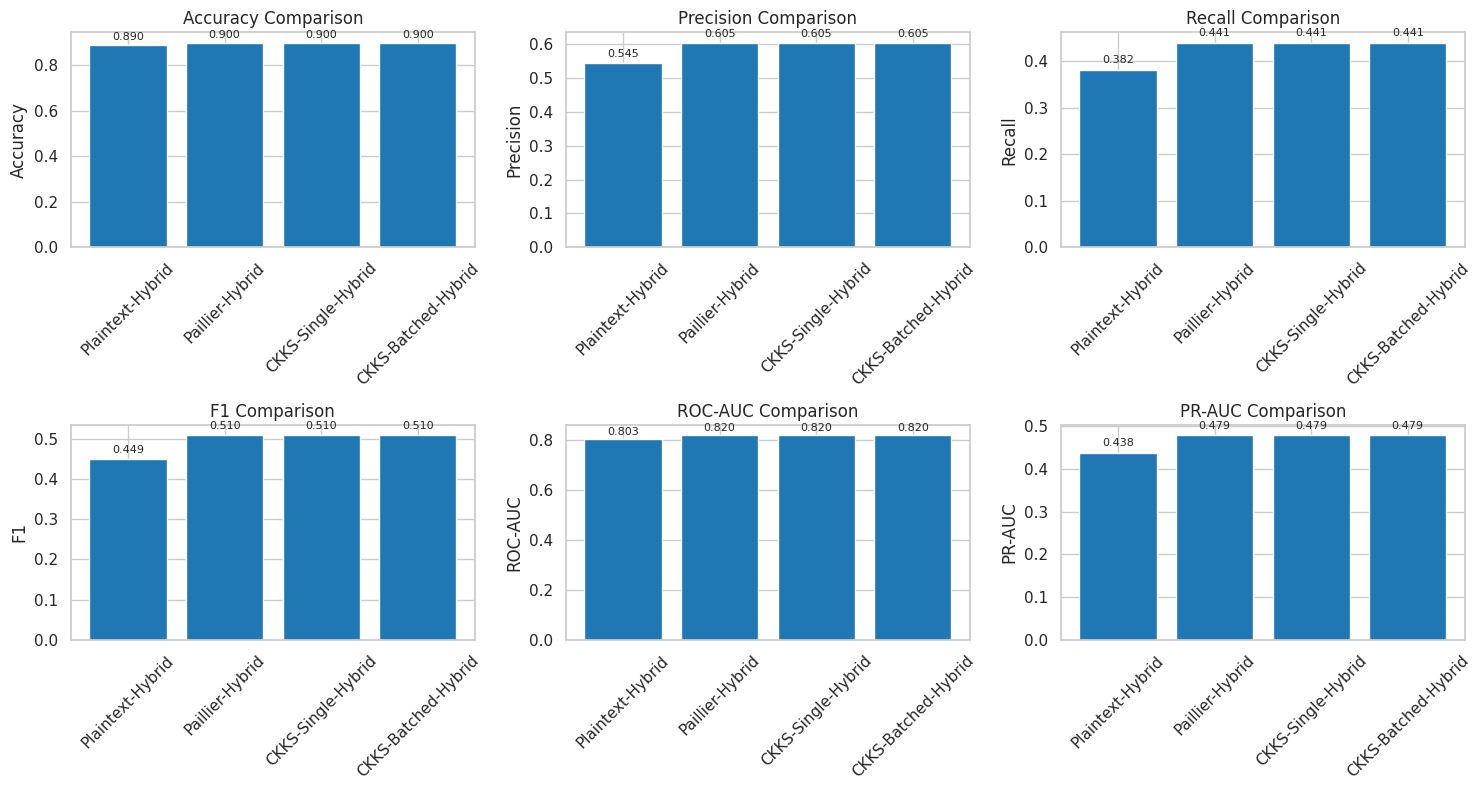

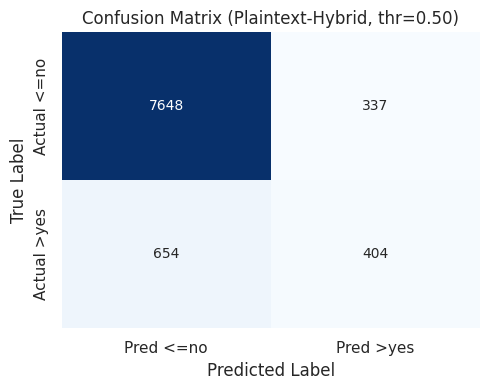

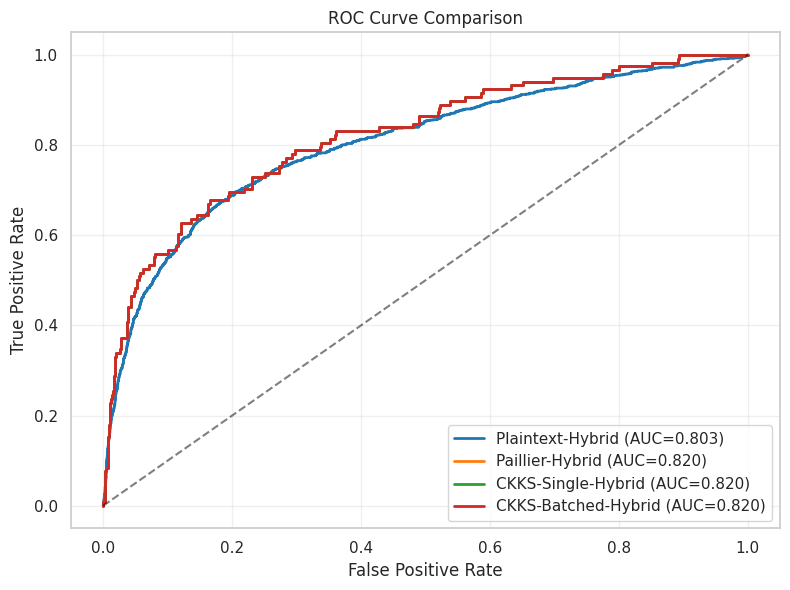

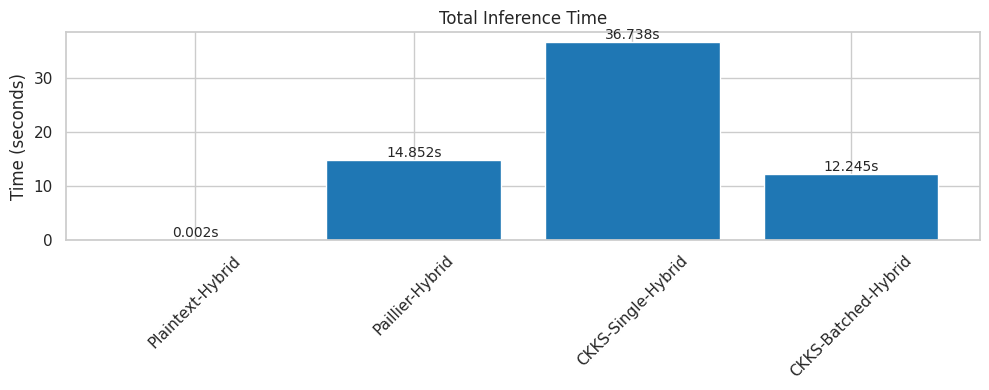


=== Timing Results ===
Plaintext-Hybrid: 0.002s
Paillier-Hybrid: 14.852s (14.9ms per sample)
CKKS-Single-Hybrid: 36.738s (36.7ms per sample)
CKKS-Batched-Hybrid: 12.245s (12.2ms per sample)

Best parameters: {'C': 0.1}, Tuned threshold: 0.500
Number of hybrid features: 18


In [ ]:
# =============================================================================
# Colab-Ready: XGBoost+MLP Hybrid with Homomorphic Encryption
# =============================================================================
# Dataset: Bank Marketing (UCI) – provided as /mnt/data/bank-full.csv
# Modes: Plaintext, Paillier, CKKS-Single, CKKS-Batched
# =============================================================================

# Install required packages (run once in Colab)
!pip install -q tenseal phe imbalanced-learn xgboost tensorflow matplotlib seaborn

import time
import tenseal as ts
import phe as paillier
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import psutil
import gc

from math import isfinite

warnings.filterwarnings('ignore')

# sklearn & imblearn
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, roc_auc_score, average_precision_score,
    precision_score, recall_score, f1_score, confusion_matrix,
    roc_curve, log_loss, brier_score_loss
)
from sklearn.feature_selection import SelectKBest, f_classif
from imblearn.over_sampling import SMOTE

# xgboost & tensorflow
import xgboost as xgb
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam

# reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

# Memory monitoring
def monitor_memory():
    process = psutil.Process()
    memory_info = process.memory_info()
    return memory_info.rss / 1024 ** 2  # MB

# ========================================
# 1) Data loading & preprocessing (Bank Marketing)
# ========================================
print("Loading and preprocessing data...")

# Path: change if necessary; expects bank-full.csv uploaded to /mnt/data/
df = pd.read_csv("/content/bank-full.csv", sep=";")

# target
y = df['y'].apply(lambda x: 1 if str(x).strip().lower() == 'yes' else 0)
df = df.drop(columns=['y'])

# Basic feature engineering
df['age_binned'] = pd.cut(df['age'], bins=5, labels=False)
df['balance_binned'] = pd.cut(df['balance'].replace([np.inf, -np.inf], np.nan).fillna(0), bins=5, labels=False)
df['duration_binned'] = pd.cut(df['duration'].replace([np.inf, -np.inf], np.nan).fillna(0), bins=5, labels=False)

# duration is usually leakage for campaign success; drop to avoid target leakage
if 'duration' in df.columns:
    df = df.drop(columns=['duration'])

# One-hot encode categorical variables (drop_first for memory)
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
df = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

# Feature selection - keep top 30 features
selector = SelectKBest(score_func=f_classif, k=min(30, df.shape[1]))
X_selected = selector.fit_transform(df, y)
selected_mask = selector.get_support()
selected_features = df.columns[selected_mask]
X = pd.DataFrame(X_selected, columns=selected_features)

# cleanup
del df
gc.collect()

# Train/val/test split (stratified)
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.2, random_state=RANDOM_STATE, stratify=y_train_full
)

# Scale (fit on train only)
scaler = StandardScaler(with_mean=True, with_std=True)
X_train_s = scaler.fit_transform(X_train)
X_val_s   = scaler.transform(X_val)
X_test_s  = scaler.transform(X_test)

# Balance classes on train only
sm = SMOTE(random_state=RANDOM_STATE, k_neighbors=5)
X_train_bal, y_train_bal = sm.fit_resample(X_train_s, y_train)

del X_train, X_val
gc.collect()

print(f"Shapes -> X_train_bal: {X_train_bal.shape}, X_val_s: {X_val_s.shape}, X_test_s: {X_test_s.shape}")

# ========================================
# 2) Hybrid XGBoost + MLP Model Training
# ========================================
print("Training Hybrid XGBoost + MLP Feature Extractor...")

# XGBoost feature extractor
xgb_model = xgb.XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    reg_alpha=0.1,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    use_label_encoder=False,
    eval_metric='logloss'
)

xgb_model.fit(X_train_bal, y_train_bal)
X_train_xgb = xgb_model.predict_proba(X_train_bal)
X_val_xgb = xgb_model.predict_proba(X_val_s)

# MLP feature extractor (small for memory)
input_dim = X_train_bal.shape[1]
hidden_units = 32

input_layer = Input(shape=(input_dim,))
hidden1 = Dense(hidden_units, activation='relu')(input_layer)
hidden2 = Dense(hidden_units // 2, activation='relu')(hidden1)
output_layer = Dense(1, activation='sigmoid')(hidden2)

mlp_model = Model(inputs=input_layer, outputs=output_layer)
mlp_model.compile(optimizer=Adam(learning_rate=0.001),
                  loss='binary_crossentropy',
                  metrics=['accuracy'])

mlp_model.fit(X_train_bal, y_train_bal,
              epochs=30, batch_size=64,
              validation_data=(X_val_s, y_val),
              verbose=0)

feature_extractor = Model(inputs=mlp_model.input, outputs=hidden2)
X_train_mlp = feature_extractor.predict(X_train_bal, verbose=0)
X_val_mlp = feature_extractor.predict(X_val_s, verbose=0)

# Combine features
X_train_hybrid = np.hstack((X_train_xgb, X_train_mlp))
X_val_hybrid = np.hstack((X_val_xgb, X_val_mlp))

# Logistic Regression meta-learner with grid search
logreg_hybrid = LogisticRegression(
    penalty="l2", solver="saga", max_iter=2000, class_weight="balanced",
    n_jobs=-1, random_state=RANDOM_STATE, tol=1e-4
)

param_grid = {'C': [0.01, 0.1, 1.0, 10.0]}
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

gs_hybrid = GridSearchCV(
    estimator=logreg_hybrid,
    param_grid=param_grid,
    scoring="average_precision",
    cv=cv,
    n_jobs=-1,
    verbose=0
)
gs_hybrid.fit(X_train_hybrid, y_train_bal)

print(f"Best parameters: {gs_hybrid.best_params_}, Best score: {gs_hybrid.best_score_:.4f}")

# Threshold tuning on validation to maximize F1
val_scores_hybrid = gs_hybrid.best_estimator_.predict_proba(X_val_hybrid)[:, 1]
thresholds = np.linspace(0.2, 0.8, 61)
best_thr, best_f1 = 0.5, -1
for t in thresholds:
    preds = (val_scores_hybrid >= t).astype(int)
    f1 = f1_score(y_val, preds, zero_division=0)
    if f1 > best_f1:
        best_f1, best_thr = f1, t
print(f"Optimal threshold: {best_thr:.3f} (F1: {best_f1:.4f})")

# Retrain on full train (train+val)
X_train_full_s = scaler.fit_transform(X_train_full)
X_train_full_bal, y_train_full_bal = sm.fit_resample(X_train_full_s, y_train_full)

# Extract features for full training data using previously trained extractors
X_train_full_xgb = xgb_model.predict_proba(X_train_full_bal)
X_train_full_mlp = feature_extractor.predict(X_train_full_bal, verbose=0)
X_train_full_hybrid = np.hstack((X_train_full_xgb, X_train_full_mlp))

best_model_final = LogisticRegression(
    penalty="l2", solver="saga", max_iter=2000, class_weight="balanced",
    n_jobs=-1, random_state=RANDOM_STATE, **gs_hybrid.best_params_
)
best_model_final.fit(X_train_full_hybrid, y_train_full_bal)

weights = best_model_final.coef_[0].astype(float)
bias = float(best_model_final.intercept_[0])

# cleanup
del X_train_bal, y_train_bal, X_train_full_bal, y_train_full_bal, X_train_full_s
gc.collect()

# ========================================
# Helpers (evaluation, sigmoid)
# ========================================
def evaluate_model(y_true, y_pred, y_score, label):
    acc   = accuracy_score(y_true, y_pred)
    prec  = precision_score(y_true, y_pred, zero_division=0)
    rec   = recall_score(y_true, y_pred, zero_division=0)
    f1    = f1_score(y_true, y_pred, zero_division=0)
    rocau = roc_auc_score(y_true, y_score) if len(np.unique(y_true)) > 1 else np.nan
    prauc = average_precision_score(y_true, y_score) if len(np.unique(y_true)) > 1 else np.nan
    ll    = log_loss(y_true, np.clip(y_score, 1e-12, 1-1e-12))
    bs    = brier_score_loss(y_true, np.clip(y_score, 1e-12, 1-1e-12))
    return {
        "Mode": label, "Accuracy": acc, "Precision": prec, "Recall": rec, "F1": f1,
        "ROC-AUC": rocau, "PR-AUC": prauc, "LogLoss": ll, "Brier": bs
    }

def sigmoid(x):
    x = np.clip(x, -500, 500)
    return 1.0 / (1.0 + np.exp(-x))

results = []

# ========================================
# 3) Plaintext Inference (with tuned threshold)
# ========================================
print("\n=== Plaintext Inference ===")
X_test_xgb = xgb_model.predict_proba(X_test_s)
X_test_mlp = feature_extractor.predict(X_test_s, verbose=0)
X_test_hybrid = np.hstack((X_test_xgb, X_test_mlp))

start = time.time()
logits = np.dot(X_test_hybrid, weights) + bias
plaintext_probs = sigmoid(logits)
plaintext_preds = (plaintext_probs >= best_thr).astype(int)
plaintext_time = time.time() - start

results.append(evaluate_model(y_test.to_numpy(), plaintext_preds, plaintext_probs, "Plaintext-Hybrid"))
print(f"[Plaintext-Hybrid] inference in {plaintext_time:.3f}s | tuned threshold = {best_thr:.3f}")

del logits
gc.collect()

# ========================================
# 4) Paillier Homomorphic Encryption
# ========================================
print("\n=== Paillier Homomorphic Encryption ===")
# Use 1024-bit for speed in Colab experiments (weaker than 2048)
pk, sk = paillier.generate_paillier_keypair(n_length=1024)

# Encrypt weights and bias (as floats)
enc_weights = [pk.encrypt(float(w)) for w in weights]
enc_bias = pk.encrypt(float(bias))

# Reduced sample size for memory
fixed_sample_size = 1000
sample_size = min(fixed_sample_size, X_test_hybrid.shape[0])
X_sample_hybrid = X_test_hybrid[:sample_size]
y_sample = y_test.to_numpy()[:sample_size]

start = time.time()
enc_logits = []
for xi in X_sample_hybrid:
    dot = enc_bias
    # dot with encrypted weights: enc(w)*x + bias
    for xij, enc_wj in zip(xi, enc_weights):
        dot = dot + enc_wj * float(xij)
    enc_logits.append(dot)

# decrypt
decrypted_logits = np.array([sk.decrypt(val) for val in enc_logits], dtype=float)
decrypted_logits[~np.isfinite(decrypted_logits)] = 0.0
paillier_probs = sigmoid(decrypted_logits)
paillier_preds = (paillier_probs >= best_thr).astype(int)
paillier_time = time.time() - start

results.append(evaluate_model(y_sample, paillier_preds, paillier_probs, "Paillier-Hybrid"))
print(f"[Paillier-Hybrid] inference ({sample_size} samples) in {paillier_time:.3f}s")

del enc_weights, enc_bias, enc_logits, decrypted_logits
gc.collect()

# ========================================
# 5) CKKS Homomorphic Encryption (Single-sample)
# ========================================
print("\n=== CKKS Homomorphic Encryption (Single-sample) ===")

def build_ckks_context(poly_mod=8192, coeff_mod_bit_sizes=[60, 40, 40, 60], scale=2**40):
    ctx = ts.context(ts.SCHEME_TYPE.CKKS, poly_mod, -1, coeff_mod_bit_sizes)
    ctx.generate_galois_keys()
    ctx.global_scale = scale
    return ctx

ckks_single_time = float('nan')
try:
    context = build_ckks_context()

    enc_weights_ckks = ts.ckks_vector(context, weights.tolist())
    enc_bias_ckks = ts.ckks_vector(context, [bias])

    start = time.time()
    enc_logits_ckks = []
    for xi in X_sample_hybrid:
        enc_xi = ts.ckks_vector(context, xi.tolist())
        dot_product = enc_xi.dot(enc_weights_ckks)
        encrypted_logit = dot_product + enc_bias_ckks
        enc_logits_ckks.append(encrypted_logit)

    # decrypt each
    decrypted_logits_ckks = np.array([vec.decrypt()[0] for vec in enc_logits_ckks], dtype=float)
    ckks_single_probs = sigmoid(decrypted_logits_ckks)
    ckks_single_preds = (ckks_single_probs >= best_thr).astype(int)
    ckks_single_time = time.time() - start

    results.append(evaluate_model(y_sample, ckks_single_preds, ckks_single_probs, "CKKS-Single-Hybrid"))
    print(f"[CKKS-Single-Hybrid] inference ({sample_size} samples) in {ckks_single_time:.3f}s")

except Exception as e:
    print(f"CKKS-Single failed: {e}")
    results.append({
        "Mode": "CKKS-Single-Hybrid", "Accuracy": np.nan, "Precision": np.nan,
        "Recall": np.nan, "F1": np.nan, "ROC-AUC": np.nan, "PR-AUC": np.nan, "LogLoss": np.nan, "Brier": np.nan
    })

# cleanup ckks single vars if present
ckks_vars = ['context', 'enc_weights_ckks', 'enc_bias_ckks', 'enc_logits_ckks', 'decrypted_logits_ckks']
for var in ckks_vars:
    if var in locals():
        del locals()[var]
gc.collect()

print(f"Memory after CKKS-Single: {monitor_memory():.2f} MB")

# ========================================
# 6) CKKS Homomorphic Encryption (Batched)
# ========================================
print("\n=== CKKS Homomorphic Encryption (Batched) ===")

ckks_batch_time = float('nan')
try:
    context = build_ckks_context()
    batch_size = min(16, sample_size)
    num_batches = int(np.ceil(sample_size / batch_size))

    start = time.time()
    decrypted_logits_batch = []

    for b in range(num_batches):
        batch_start = b * batch_size
        batch_end = min((b + 1) * batch_size, sample_size)
        current_bs = batch_end - batch_start
        batch_samples = X_sample_hybrid[batch_start:batch_end]

        weighted_sum = None
        for j in range(batch_samples.shape[1]):
            col_data = batch_samples[:, j].astype(float).tolist()
            enc_col = ts.ckks_vector(context, col_data)
            weighted_col = enc_col * float(weights[j])
            weighted_sum = weighted_col if weighted_sum is None else (weighted_sum + weighted_col)

        batch_bias = ts.ckks_vector(context, [float(bias)] * current_bs)
        encrypted_logits_batch = weighted_sum + batch_bias

        decrypted_logits_batch.extend(encrypted_logits_batch.decrypt())

    decrypted_logits_batch = np.array(decrypted_logits_batch, dtype=float)
    ckks_batch_probs = sigmoid(decrypted_logits_batch)
    ckks_batch_preds = (ckks_batch_probs >= best_thr).astype(int)
    ckks_batch_time = time.time() - start

    results.append(evaluate_model(y_sample[:len(ckks_batch_preds)], ckks_batch_preds, ckks_batch_probs, "CKKS-Batched-Hybrid"))
    print(f"[CKKS-Batched-Hybrid] inference ({len(ckks_batch_preds)} samples) in {ckks_batch_time:.3f}s")

except Exception as e:
    print(f"CKKS-Batched failed: {e}")
    results.append({
        "Mode": "CKKS-Batched-Hybrid", "Accuracy": np.nan, "Precision": np.nan,
        "Recall": np.nan, "F1": np.nan, "ROC-AUC": np.nan, "PR-AUC": np.nan, "LogLoss": np.nan, "Brier": np.nan
    })

# cleanup ckks batch vars if present
ckks_batch_vars = ['context', 'weighted_sum', 'batch_bias', 'encrypted_logits_batch', 'decrypted_logits_batch']
for var in ckks_batch_vars:
    if var in locals():
        del locals()[var]
gc.collect()

print(f"Memory after CKKS-Batched: {monitor_memory():.2f} MB")

# ========================================
# 7) Results Analysis & Plots
# ========================================
df_results = pd.DataFrame(results)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1500)
print("\n=== Evaluation Results ===")
print(df_results.round(4))

# Degradation vs plaintext
if 'Plaintext-Hybrid' in df_results['Mode'].values:
    plaintext_metrics = df_results[df_results['Mode'] == 'Plaintext-Hybrid'].iloc[0]
    degradation = []
    for _, row in df_results.iterrows():
        if row['Mode'] != 'Plaintext-Hybrid' and not np.isnan(row['Accuracy']):
            deg = {
                'Mode': row['Mode'],
                'Accuracy_Degradation': (plaintext_metrics['Accuracy'] - row['Accuracy']) / plaintext_metrics['Accuracy'] * 100 if plaintext_metrics['Accuracy'] != 0 else np.nan,
                'F1_Degradation': (plaintext_metrics['F1'] - row['F1']) / plaintext_metrics['F1'] * 100 if plaintext_metrics['F1'] != 0 else np.nan,
            }
            degradation.append(deg)

    if degradation:
        df_degradation = pd.DataFrame(degradation)
        print("\n=== Performance Degradation vs Plaintext (%) ===")
        print(df_degradation.round(2))
    else:
        print("\nNo encrypted models produced valid results for degradation comparison")
else:
    print("\nPlaintext results missing - skipping degradation calculation")

# Simple visualizations (kept small for Colab)
sns.set_context("notebook")
sns.set_style("whitegrid")
plt.rcParams['font.size'] = 10

# Metrics plotting (only existing numeric metrics)
metrics = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC']
present_metrics = [m for m in metrics if m in df_results.columns]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()
for i, metric in enumerate(present_metrics):
    vals = df_results[metric].fillna(0).values
    bars = axes[i].bar(df_results['Mode'], vals)
    axes[i].set_title(f'{metric} Comparison')
    axes[i].set_ylabel(metric)
    axes[i].tick_params(axis='x', rotation=45)
    for bar in bars:
        h = bar.get_height()
        axes[i].text(bar.get_x() + bar.get_width() / 2., h + 0.01, f'{h:.3f}', ha='center', va='bottom', fontsize=8)

# hide unused subplots
for j in range(len(present_metrics), 6):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

# Confusion matrix for Plaintext
if 'Plaintext-Hybrid' in df_results['Mode'].values:
    cm = confusion_matrix(y_test.to_numpy(), plaintext_preds)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=['Pred <=no', 'Pred >yes'],
                yticklabels=['Actual <=no', 'Actual >yes'])
    plt.title(f"Confusion Matrix (Plaintext-Hybrid, thr={best_thr:.2f})")
    plt.ylabel("True Label")
    plt.xlabel("Predicted Label")
    plt.tight_layout()
    plt.show()

# ROC curves
plt.figure(figsize=(8, 6))
if len(np.unique(y_test)) > 1:
    try:
        fpr, tpr, _ = roc_curve(y_test.to_numpy(), plaintext_probs)
        auc_plain = roc_auc_score(y_test.to_numpy(), plaintext_probs)
        plt.plot(fpr, tpr, label=f'Plaintext-Hybrid (AUC={auc_plain:.3f})', linewidth=2)
    except Exception:
        pass

if 'Paillier-Hybrid' in df_results['Mode'].values and not np.isnan(df_results[df_results['Mode'] == 'Paillier-Hybrid']['ROC-AUC'].values[0]):
    try:
        fpr_p, tpr_p, _ = roc_curve(y_sample, paillier_probs)
        plt.plot(fpr_p, tpr_p, label=f'Paillier-Hybrid (AUC={roc_auc_score(y_sample, paillier_probs):.3f})', linewidth=2)
    except Exception:
        pass

if 'CKKS-Single-Hybrid' in df_results['Mode'].values and 'ckks_single_probs' in locals():
    try:
        fpr_cs, tpr_cs, _ = roc_curve(y_sample, ckks_single_probs)
        plt.plot(fpr_cs, tpr_cs, label=f'CKKS-Single-Hybrid (AUC={roc_auc_score(y_sample, ckks_single_probs):.3f})', linewidth=2)
    except Exception:
        pass

if 'CKKS-Batched-Hybrid' in df_results['Mode'].values and 'ckks_batch_probs' in locals():
    try:
        fpr_cb, tpr_cb, _ = roc_curve(y_sample[:len(ckks_batch_probs)], ckks_batch_probs)
        plt.plot(fpr_cb, tpr_cb, label=f'CKKS-Batched-Hybrid (AUC={roc_auc_score(y_sample[:len(ckks_batch_probs)], ckks_batch_probs):.3f})', linewidth=2)
    except Exception:
        pass

plt.plot([0, 1], [0, 1], 'k--', alpha=0.5)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Timing comparison
timing_data = {
    'Method': ['Plaintext-Hybrid', 'Paillier-Hybrid', 'CKKS-Single-Hybrid', 'CKKS-Batched-Hybrid'],
    'Time (s)': [float(plaintext_time), float(paillier_time),
                float(ckks_single_time) if not np.isnan(ckks_single_time) else 0,
                float(ckks_batch_time) if not np.isnan(ckks_batch_time) else 0]
}

timing_data['Time per sample (ms)'] = [0] * len(timing_data['Method'])
for i, method in enumerate(timing_data['Method']):
    if method != 'Plaintext-Hybrid' and sample_size > 0:
        timing_data['Time per sample (ms)'][i] = timing_data['Time (s)'][i] / sample_size * 1000

plt.figure(figsize=(10, 4))
bars = plt.bar(timing_data['Method'], timing_data['Time (s)'])
plt.title('Total Inference Time')
plt.ylabel('Time (seconds)')
plt.xticks(rotation=45)
for bar in bars:
    height = bar.get_height()
    if height > 0:
        plt.text(bar.get_x() + bar.get_width()/2., height + 0.01, f'{height:.3f}s', ha='center', va='bottom')
plt.tight_layout()
plt.show()

print("\n=== Timing Results ===")
for i, m in enumerate(timing_data['Method']):
    if m == 'Plaintext-Hybrid':
        print(f"{m}: {timing_data['Time (s)'][i]:.3f}s")
    else:
        print(f"{m}: {timing_data['Time (s)'][i]:.3f}s ({timing_data['Time per sample (ms)'][i]:.1f}ms per sample)")

print(f"\nBest parameters: {gs_hybrid.best_params_}, Tuned threshold: {best_thr:.3f}")
print(f"Number of hybrid features: {len(weights)}")




# **eICU Dataset 300 Samples**

Loading eICU patient CSV...
Train shapes: (1594, 14) Balanced shape for MLP: (2916, 14)
Training XGBoost...
Training MLP feature extractor...
Plaintext done
Paillier done
CKKS single done
CKKS batched done

=== Results for sample size 300 ===
   Accuracy  Precision  Recall      F1  ROC-AUC  PR-AUC  LogLoss   Brier  \
0      0.85     0.2692  0.2121  0.2373   0.6124  0.2461   0.6337  0.1787   
1      0.85     0.2692  0.2121  0.2373   0.6124  0.2461   0.6337  0.1787   
2      0.85     0.2692  0.2121  0.2373   0.6124  0.2461   0.6337  0.1787   
3      0.85     0.2692  0.2121  0.2373   0.6124  0.2461   0.6337  0.1787   

                  Mode  SampleSize  Time(s)  
0     Plaintext-Hybrid         300   0.0005  
1      Paillier-Hybrid         300   8.2508  
2   CKKS-Single-Hybrid         300  25.0631  
3  CKKS-Batched-Hybrid         300  10.0781  


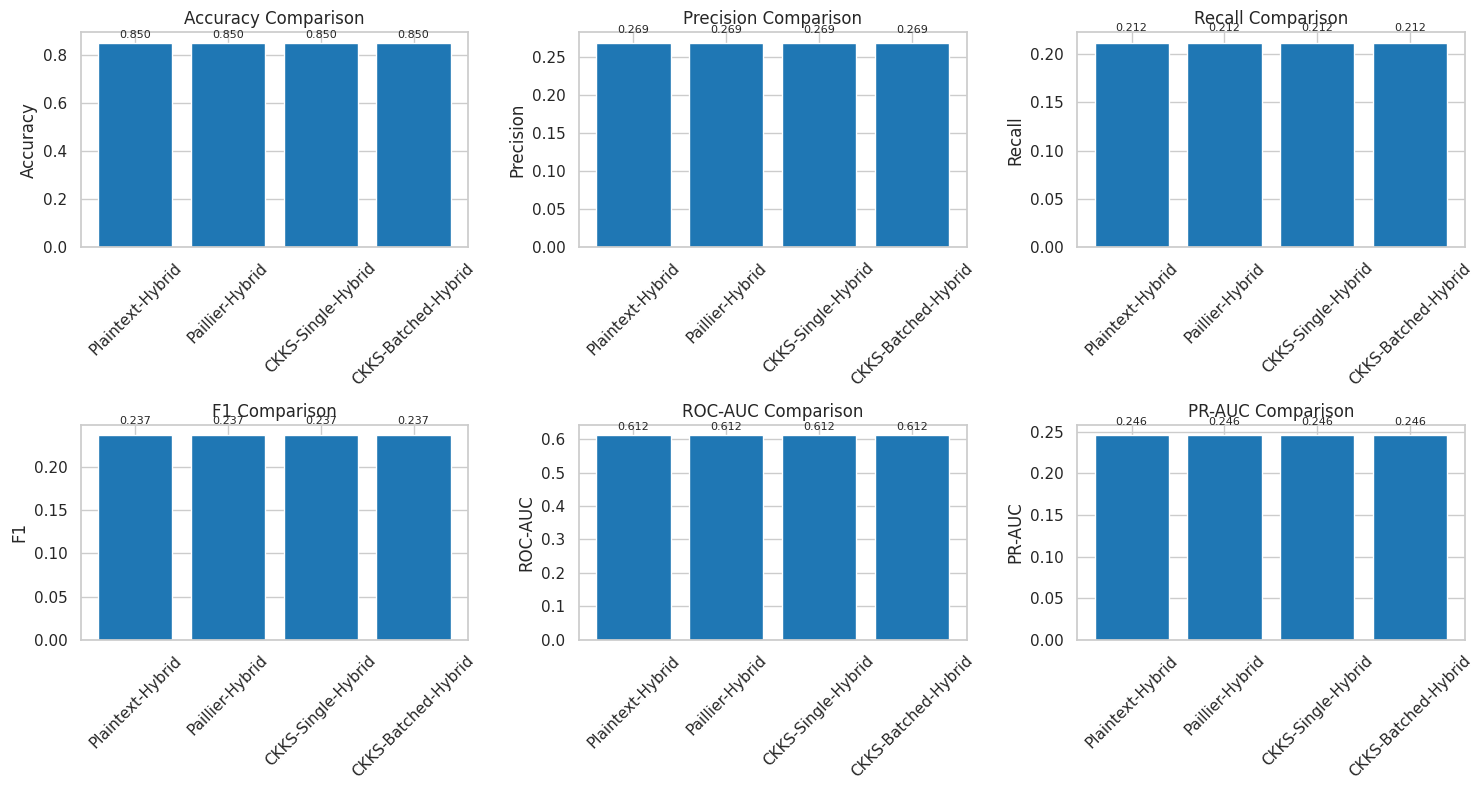

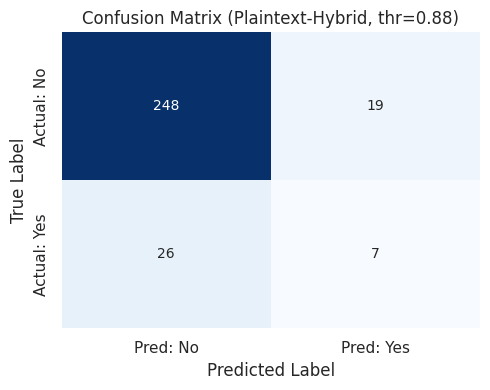

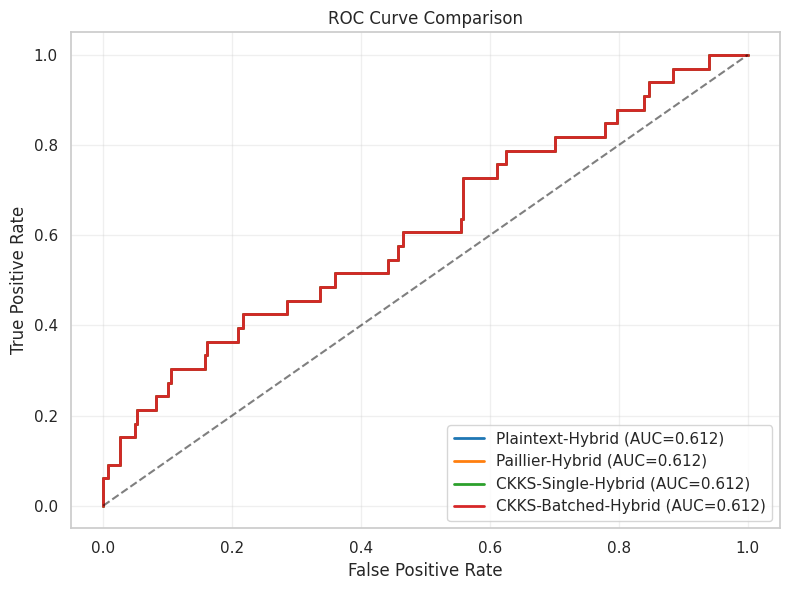

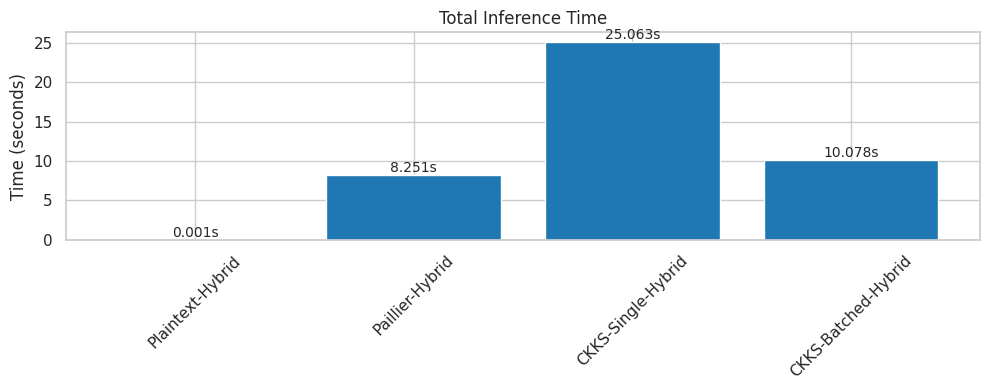

In [12]:
# =============================================================================
# Hybrid XGBoost + MLP + Homomorphic Inference on 300 test samples (improved)
# =============================================================================
# Changes:
# - Safer preprocessing, minor feature engineering cleanups
# - XGBoost: tuned params + optional early stopping (with try/except)
# - MLP: BatchNorm + L2 + Dropout + LR scheduling
# - Cleaner SMOTE fallback
# - Fixed ROC curves (variable names + safe checks)
# - Plots: labels/legends and robust handling
# =============================================================================

# (Optional) Colab installs
# !pip install -q tenseal phe imbalanced-learn xgboost tensorflow matplotlib seaborn psutil requests

import os, time, gc, requests, psutil, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import tenseal as ts
import phe as paillier

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, log_loss, brier_score_loss,
    confusion_matrix, roc_curve
)
from sklearn.feature_selection import SelectKBest, f_classif
from imblearn.over_sampling import SMOTE

import xgboost as xgb
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Input, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

def monitor_memory_mb():
    return psutil.Process().memory_info().rss / 1024**2

# ------------------ Data loader ------------------
def load_eicu_patient_csv():
    url = "https://physionet.org/files/eicu-crd-demo/2.0.1/patient.csv.gz"
    local = "/tmp/patient.csv.gz"
    try:
        return pd.read_csv(url, compression='gzip', low_memory=False)
    except Exception:
        with requests.get(url, stream=True, timeout=60) as r:
            r.raise_for_status()
            with open(local, "wb") as fh:
                for chunk in r.iter_content(chunk_size=8192):
                    if chunk:
                        fh.write(chunk)
        df = pd.read_csv(local, compression='gzip', low_memory=False)
        try: os.remove(local)
        except: pass
        return df

# ------------------ Main pipeline ------------------
SAMPLE_TARGET = 300

print("Loading eICU patient CSV...")
df_raw = load_eicu_patient_csv()

if 'hospitaldischargestatus' not in df_raw.columns:
    raise ValueError("Expected 'hospitaldischargestatus' column not found.")

# target
df = df_raw.dropna(subset=['hospitaldischargestatus']).copy()
y = df['hospitaldischargestatus'].apply(lambda x: 1 if str(x).strip().lower() == 'expired' else 0)

# candidates
candidate = [
    'age','gender','ethnicity','apacheadmissiondx','hospitaladmitsource',
    'unitadmitsource','unitadmittime24','admissionheight','admissionweight',
    'hospitaladmitoffset','hospitaldischargeoffset'
]
available = [c for c in candidate if c in df.columns]
X_df = df[available].copy()

# encoding
if 'gender' in X_df.columns:
    X_df['gender'] = LabelEncoder().fit_transform(X_df['gender'].astype(str))

for c in ['apacheadmissiondx','hospitaladmitsource','unitadmitsource','ethnicity']:
    if c in X_df.columns:
        freq = X_df[c].astype(str).value_counts(normalize=True)
        X_df[c] = X_df[c].astype(str).map(freq).fillna(0.0)

# numeric coercion
for c in X_df.columns:
    if not pd.api.types.is_numeric_dtype(X_df[c]):
        X_df[c] = pd.to_numeric(X_df[c], errors='coerce')

# BMI
if ('admissionheight' in X_df.columns) and ('admissionweight' in X_df.columns):
    h = pd.to_numeric(X_df['admissionheight'], errors='coerce')
    w = pd.to_numeric(X_df['admissionweight'], errors='coerce')
    bmi = pd.Series(np.nan, index=X_df.index)
    valid = (h > 30) & (w > 0)
    with np.errstate(divide='ignore', invalid='ignore'):
        bmi.loc[valid] = w.loc[valid] / ((h.loc[valid] / 100.0) ** 2)
    X_df['bmi'] = bmi

# age features
if 'age' in X_df.columns:
    age_num = pd.to_numeric(X_df['age'], errors='coerce').fillna(0)
    X_df['age2'] = age_num ** 2
    X_df['age_bin'] = pd.cut(age_num, bins=5, labels=False).astype(float)

# clean NaNs/inf
X_df.replace([np.inf, -np.inf], np.nan, inplace=True)
for c in X_df.columns:
    if X_df[c].isna().any():
        med = X_df[c].median()
        X_df[c] = X_df[c].fillna(med if not pd.isna(med) else 0.0)

# final numeric
X_df = X_df.apply(pd.to_numeric, errors='coerce').fillna(0.0)
usable = X_df.shape[0]

# feature selection
k_sel = min(30, max(1, X_df.shape[1]))
selector = SelectKBest(score_func=f_classif, k=k_sel)
try:
    selector.fit(X_df, y)
    mask = selector.get_support()
    selected = X_df.columns[mask]
    X = pd.DataFrame(selector.transform(X_df), columns=selected)
except Exception:
    X = X_df.copy()
    selected = X.columns

# free memory
del df_raw
gc.collect()

# splits
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.20, random_state=RANDOM_STATE, stratify=y_train_full
)

# scaling
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s   = scaler.transform(X_val)
X_test_s  = scaler.transform(X_test)

# SMOTE (safe)
minority_count = int(np.sum(y_train == 1))
small_dataset = usable < 1000
if small_dataset and minority_count < 10:
    X_train_bal, y_train_bal = X_train_s, y_train
else:
    sm = SMOTE(random_state=RANDOM_STATE, k_neighbors=min(5, max(1, minority_count-1)))
    try:
        X_train_bal, y_train_bal = sm.fit_resample(X_train_s, y_train)
    except Exception:
        X_train_bal, y_train_bal = X_train_s, y_train

print("Train shapes:", X_train_s.shape, "Balanced shape for MLP:", X_train_bal.shape)

# adaptive HPs
xgb_n_estimators = 80 if small_dataset else 400
mlp_epochs = 25 if small_dataset else 60

# XGBoost
pos = np.sum(y_train == 1)
neg = np.sum(y_train == 0)
scale_pos_weight = float(neg / pos) if pos > 0 else 1.0

xgb_model = xgb.XGBClassifier(
    n_estimators=xgb_n_estimators,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.9,
    reg_lambda=1.5,
    reg_alpha=0.2,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    tree_method="hist",
    use_label_encoder=False,
    eval_metric="logloss",
    scale_pos_weight=scale_pos_weight
)

print("Training XGBoost...")
# Try early stopping if version supports it; otherwise plain fit
try:
    xgb_model.fit(
        X_train_s, y_train,
        eval_set=[(X_val_s, y_val)],
        verbose=False,
        early_stopping_rounds=50
    )
except TypeError:
    xgb_model.fit(X_train_s, y_train, eval_set=[(X_val_s, y_val)], verbose=False)

# XGB features (probabilities)
X_train_xgb = xgb_model.predict_proba(X_train_bal)
X_val_xgb   = xgb_model.predict_proba(X_val_s)
X_test_xgb  = xgb_model.predict_proba(X_test_s)

# MLP feature extractor (regularized)
input_dim = X_train_bal.shape[1]
inp = Input(shape=(input_dim,))
h = Dense(128, activation='relu', kernel_regularizer=l2(1e-4))(inp)
h = BatchNormalization()(h)
h = Dropout(0.4)(h)
h = Dense(64, activation='relu', kernel_regularizer=l2(1e-4))(h)
h = BatchNormalization()(h)
h = Dropout(0.3)(h)
feat = Dense(16, activation='relu', kernel_regularizer=l2(1e-4))(h)
out  = Dense(1, activation='sigmoid')(feat)
mlp_model = Model(inputs=inp, outputs=out)
mlp_model.compile(optimizer=Adam(1e-3), loss='binary_crossentropy', metrics=['accuracy'])

callbacks = [
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-5, verbose=0),
    EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=0)
]

print("Training MLP feature extractor...")
batch_size = 32 if not small_dataset else 16
mlp_model.fit(
    X_train_bal, y_train_bal,
    epochs=mlp_epochs,
    batch_size=batch_size,
    validation_data=(X_val_s, y_val),
    callbacks=callbacks,
    verbose=0
)
feature_extractor = Model(inputs=mlp_model.input, outputs=feat)
X_train_mlp = feature_extractor.predict(X_train_bal, verbose=0)
X_val_mlp   = feature_extractor.predict(X_val_s,   verbose=0)
X_test_mlp  = feature_extractor.predict(X_test_s,  verbose=0)

# Meta-learner
X_train_hybrid = np.hstack((X_train_xgb, X_train_mlp))
X_val_hybrid   = np.hstack((X_val_xgb,   X_val_mlp))

logreg = LogisticRegression(
    penalty='l2', solver='saga', max_iter=3000,
    class_weight='balanced', n_jobs=-1, random_state=RANDOM_STATE
)
param_grid = {'C':[0.01, 0.1, 1.0]} if small_dataset else {'C':[0.01, 0.1, 1.0, 10.0]}
cv = StratifiedKFold(n_splits=2 if small_dataset else 3, shuffle=True, random_state=RANDOM_STATE)
gs = GridSearchCV(logreg, param_grid, scoring='average_precision', cv=cv, n_jobs=-1, verbose=0)
gs.fit(X_train_hybrid, y_train_bal)

# Threshold tuning on validation
val_scores = gs.best_estimator_.predict_proba(X_val_hybrid)[:,1]
best_thr, best_f1 = 0.5, -1
for t in np.linspace(0.1, 0.9, 81):
    p = (val_scores >= t).astype(int)
    f = f1_score(y_val, p, zero_division=0)
    if f > best_f1:
        best_f1, best_thr = f, t

# Retrain meta-learner on train+val (with SMOTE on full if possible)
X_train_full_s = scaler.transform(X_train_full)
try:
    k_nei = min(5, max(1, int(np.sum(y_train_full) - 1)))
    sm_full = SMOTE(random_state=RANDOM_STATE, k_neighbors=k_nei)
    X_train_full_bal, y_train_full_bal = sm_full.fit_resample(X_train_full_s, y_train_full)
except Exception:
    X_train_full_bal, y_train_full_bal = X_train_full_s, y_train_full

X_train_full_xgb  = xgb_model.predict_proba(X_train_full_bal)
X_train_full_mlp  = feature_extractor.predict(X_train_full_bal, verbose=0)
X_train_full_hybrid = np.hstack((X_train_full_xgb, X_train_full_mlp))

best_model_final = LogisticRegression(
    penalty='l2', solver='saga', max_iter=3000,
    class_weight='balanced', n_jobs=-1, random_state=RANDOM_STATE, **gs.best_params_
)
best_model_final.fit(X_train_full_hybrid, y_train_full_bal)

weights = best_model_final.coef_[0].astype(float)
bias = float(best_model_final.intercept_[0])

# Test hybrid features
X_test_hybrid = np.hstack((X_test_xgb, X_test_mlp))
available_test = X_test_hybrid.shape[0]

# Select 300 (or less if not enough)
use_n = min(SAMPLE_TARGET, available_test)
if use_n < SAMPLE_TARGET:
    print(f"Note: only {available_test} test rows available, using {use_n} instead of requested {SAMPLE_TARGET}.")

rng = np.random.RandomState(RANDOM_STATE + 1)
idx = rng.choice(available_test, size=use_n, replace=False)
X_sample = X_test_hybrid[idx]
y_sample = y_test.to_numpy()[idx]

# ------------------ Helpers ------------------
def sigmoid(x):
    x = np.clip(x, -500, 500)
    return 1.0 / (1.0 + np.exp(-x))

def eval_metrics(y_true, probs, thr):
    preds = (probs >= thr).astype(int)
    uniq = np.unique(y_true)
    has_posneg = len(uniq) > 1
    return {
        "Accuracy": accuracy_score(y_true, preds),
        "Precision": precision_score(y_true, preds, zero_division=0),
        "Recall": recall_score(y_true, preds, zero_division=0),
        "F1": f1_score(y_true, preds, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, probs) if has_posneg else np.nan,
        "PR-AUC": average_precision_score(y_true, probs) if has_posneg else np.nan,
        "LogLoss": log_loss(y_true, np.clip(probs,1e-12,1-1e-12)),
        "Brier": brier_score_loss(y_true, np.clip(probs,1e-12,1-1e-12))
    }

results = []
probs_dict = {}   # store for ROC

# ------------------ Plaintext ------------------
t0 = time.time()
logits_plain = np.dot(X_sample, weights) + bias
probs_plain  = sigmoid(logits_plain)
plaintext_preds = (probs_plain >= best_thr).astype(int)
t_plain = time.time() - t0
m_plain = eval_metrics(y_sample, probs_plain, best_thr)
m_plain.update({"Mode":"Plaintext-Hybrid","SampleSize":use_n,"Time(s)":t_plain})
results.append(m_plain)
probs_dict['Plaintext-Hybrid'] = probs_plain
print("Plaintext done")

# ------------------ Paillier ------------------
t0 = time.time()
pk, sk = paillier.generate_paillier_keypair(n_length=1024)
enc_w = [pk.encrypt(float(w)) for w in weights]
enc_b = pk.encrypt(float(bias))
enc_logits = []
for xi in X_sample:
    dot = enc_b
    for xij, ew in zip(xi, enc_w):
        dot = dot + ew * float(xij)
    enc_logits.append(dot)
dec_logits = np.array([sk.decrypt(v) for v in enc_logits], dtype=float)
dec_logits[~np.isfinite(dec_logits)] = 0.0
probs_paillier = sigmoid(dec_logits)
t_paillier = time.time() - t0
m_p = eval_metrics(y_sample, probs_paillier, best_thr)
m_p.update({"Mode":"Paillier-Hybrid","SampleSize":use_n,"Time(s)":t_paillier})
results.append(m_p)
probs_dict['Paillier-Hybrid'] = probs_paillier
print("Paillier done")

# ------------------ CKKS single ------------------
t_ckks_single = np.nan
try:
    t0 = time.time()
    ctx = ts.context(ts.SCHEME_TYPE.CKKS, 8192, -1, [60,40,40,60])
    ctx.global_scale = 2**40
    ctx.generate_galois_keys()
    enc_w_ckks = ts.ckks_vector(ctx, weights.tolist())
    enc_b_ckks = ts.ckks_vector(ctx, [bias])
    enc_logits_ckks = []
    for xi in X_sample:
        enc_x = ts.ckks_vector(ctx, xi.tolist())
        dp = enc_x.dot(enc_w_ckks)
        enc_logits_ckks.append(dp + enc_b_ckks)
    dec_logits_ckks = np.array([v.decrypt()[0] for v in enc_logits_ckks], dtype=float)
    probs_ckks_single = sigmoid(dec_logits_ckks)
    t_ckks_single = time.time() - t0
    m_cs = eval_metrics(y_sample, probs_ckks_single, best_thr)
    m_cs.update({"Mode":"CKKS-Single-Hybrid","SampleSize":use_n,"Time(s)":t_ckks_single})
    results.append(m_cs)
    probs_dict['CKKS-Single-Hybrid'] = probs_ckks_single
    print("CKKS single done")
except Exception as e:
    print(f"CKKS single failed: {e}")
    results.append({"Mode":"CKKS-Single-Hybrid","SampleSize":use_n,"Time(s)":np.nan})

# ------------------ CKKS batched ------------------
t_ckks_batch = np.nan
try:
    t0 = time.time()
    ctx = ts.context(ts.SCHEME_TYPE.CKKS, 8192, -1, [60,40,40,60])
    ctx.global_scale = 2**40
    ctx.generate_galois_keys()
    batch_size = min(16, use_n)
    num_batches = int(np.ceil(use_n / batch_size))
    dec_logits_batch = []
    for b in range(num_batches):
        s = b * batch_size
        e = min((b+1) * batch_size, use_n)
        block = X_sample[s:e]
        weighted_sum = None
        for j in range(block.shape[1]):
            col = block[:, j].astype(float).tolist()
            enc_col = ts.ckks_vector(ctx, col)
            part = enc_col * float(weights[j])
            weighted_sum = part if weighted_sum is None else (weighted_sum + part)
        bias_vec = ts.ckks_vector(ctx, [float(bias)] * (e - s))
        enc_block_logits = weighted_sum + bias_vec
        dec_logits_batch.extend(enc_block_logits.decrypt())
    dec_logits_batch = np.array(dec_logits_batch, dtype=float)
    probs_ckks_batch = sigmoid(dec_logits_batch)
    t_ckks_batch = time.time() - t0
    m_cb = eval_metrics(y_sample[:len(probs_ckks_batch)], probs_ckks_batch, best_thr)
    m_cb.update({"Mode":"CKKS-Batched-Hybrid","SampleSize":use_n,"Time(s)":t_ckks_batch})
    results.append(m_cb)
    probs_dict['CKKS-Batched-Hybrid'] = probs_ckks_batch
    print("CKKS batched done")
except Exception as e:
    print(f"CKKS batched failed: {e}")
    results.append({"Mode":"CKKS-Batched-Hybrid","SampleSize":use_n,"Time(s)":np.nan})

# ------------------ Consolidate & Save ------------------
df_results = pd.DataFrame(results)
pd.set_option("display.max_columns", None)
print(f"\n=== Results for sample size {use_n} ===")
print(df_results.round(4))

outcsv = "results_300.csv"
df_results.to_csv(outcsv, index=False)

# ------------------ Visualizations ------------------
sns.set_context("notebook")
sns.set_style("whitegrid")
plt.rcParams['font.size'] = 10

# Metric bars
metrics = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC']
present_metrics = [m for m in metrics if m in df_results.columns]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()
for i, metric in enumerate(present_metrics):
    vals = df_results[metric].fillna(0).values
    bars = axes[i].bar(df_results['Mode'], vals)
    axes[i].set_title(f'{metric} Comparison')
    axes[i].set_ylabel(metric)
    axes[i].tick_params(axis='x', rotation=45)
    for bar in bars:
        h = bar.get_height()
        axes[i].text(bar.get_x() + bar.get_width() / 2., h + 0.01, f'{h:.3f}', ha='center', va='bottom', fontsize=8)

# hide unused subplots
for j in range(len(present_metrics), 6):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

# Confusion matrix (Plaintext)
if 'Plaintext-Hybrid' in df_results['Mode'].values:
    cm = confusion_matrix(y_sample, plaintext_preds)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=['Pred: No', 'Pred: Yes'],
                yticklabels=['Actual: No', 'Actual: Yes'])
    plt.title(f"Confusion Matrix (Plaintext-Hybrid, thr={best_thr:.2f})")
    plt.ylabel("True Label")
    plt.xlabel("Predicted Label")
    plt.tight_layout()
    plt.show()

# ------------------ FIXED ROC CURVES ------------------
plt.figure(figsize=(8, 6))

def safe_plot_roc(name, y_true, probs):
    """Plot ROC if valid; return True if plotted."""
    if probs is None: return False
    y_true = np.asarray(y_true)
    probs  = np.asarray(probs)
    if len(np.unique(y_true)) < 2:
        return False
    try:
        fpr, tpr, _ = roc_curve(y_true, probs)
        auc_val = roc_auc_score(y_true, probs)
        plt.plot(fpr, tpr, label=f'{name} (AUC={auc_val:.3f})', linewidth=2)
        return True
    except Exception:
        return False

# Use the *sample* set for fair comparison across modes
plotted_any = False
plotted_any |= safe_plot_roc('Plaintext-Hybrid', y_sample, probs_dict.get('Plaintext-Hybrid'))
plotted_any |= safe_plot_roc('Paillier-Hybrid',  y_sample, probs_dict.get('Paillier-Hybrid'))
plotted_any |= safe_plot_roc('CKKS-Single-Hybrid', y_sample, probs_dict.get('CKKS-Single-Hybrid'))
plotted_any |= safe_plot_roc('CKKS-Batched-Hybrid', y_sample[:len(probs_dict.get('CKKS-Batched-Hybrid', []))],
                             probs_dict.get('CKKS-Batched-Hybrid'))

plt.plot([0, 1], [0, 1], 'k--', alpha=0.5)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison" if plotted_any else "ROC Curve (insufficient class variance)")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------ Timing comparison ------------------
t_plain_f   = float(t_plain)
t_paillier_f= float(t_paillier)
t_ckks_s_f  = float(t_ckks_single) if not np.isnan(t_ckks_single) else 0.0
t_ckks_b_f  = float(t_ckks_batch)  if not np.isnan(t_ckks_batch)  else 0.0

timing_data = {
    'Method': ['Plaintext-Hybrid', 'Paillier-Hybrid', 'CKKS-Single-Hybrid', 'CKKS-Batched-Hybrid'],
    'Time (s)': [t_plain_f, t_paillier_f, t_ckks_s_f, t_ckks_b_f]
}
if use_n > 0:
    time_per = [t_plain_f/use_n*1000, t_paillier_f/use_n*1000,
                (t_ckks_s_f/use_n*1000 if t_ckks_s_f>0 else 0),
                (t_ckks_b_f/use_n*1000 if t_ckks_b_f>0 else 0)]
else:
    time_per = [0,0,0,0]

plt.figure(figsize=(10, 4))
bars = plt.bar(timing_data['Method'], timing_data['Time (s)'])
plt.title('Total Inference Time')
plt.ylabel('Time (seconds)')
plt.xticks(rotation=45)
for bar in bars:
    height = bar.get_height()
    if height > 0:
        plt.text(bar.get_x() + bar.get_width()/2., height + 0.01, f'{height:.3f}s', ha='center', va='bottom')
plt.tight_layout()
plt.show()


# **eICU Dataset 500 Samples**

Loading eICU patient CSV...
Train shapes: (1594, 14) Balanced shape for MLP: (2916, 14)
Training XGBoost...
Training MLP feature extractor...
Note: only 499 test rows available, using 499 instead of requested 500.
Plaintext done
Paillier done
CKKS single done
CKKS batched done

=== Results for sample size 499 ===
   Accuracy  Precision  Recall      F1  ROC-AUC  PR-AUC  LogLoss   Brier  \
0    0.8818     0.3023  0.3095  0.3059   0.6007  0.2219   0.5934  0.1685   
1    0.8818     0.3023  0.3095  0.3059   0.6007  0.2219   0.5934  0.1685   
2    0.8818     0.3023  0.3095  0.3059   0.6007  0.2219   0.5934  0.1685   
3    0.8818     0.3023  0.3095  0.3059   0.6007  0.2219   0.5934  0.1685   

                  Mode  SampleSize  Time(s)  
0     Plaintext-Hybrid         499   0.0003  
1      Paillier-Hybrid         499  10.9189  
2   CKKS-Single-Hybrid         499  18.7210  
3  CKKS-Batched-Hybrid         499   7.9462  


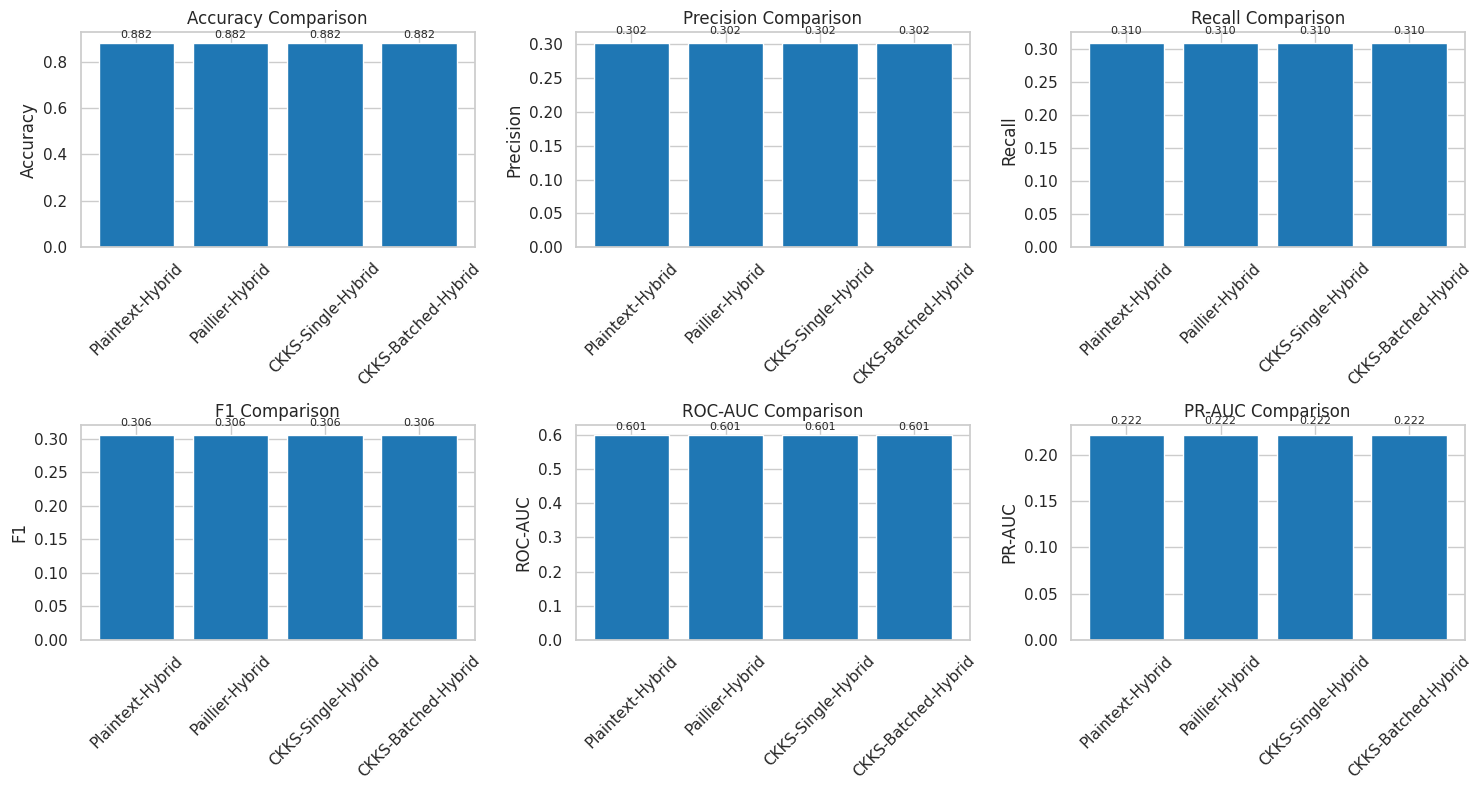

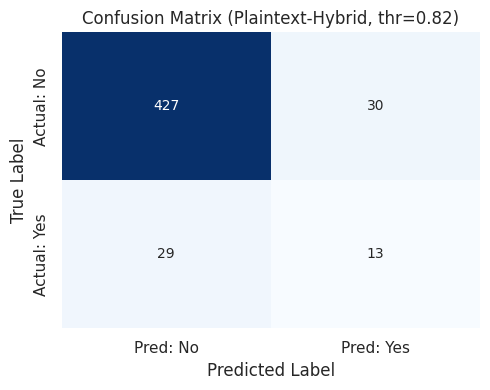

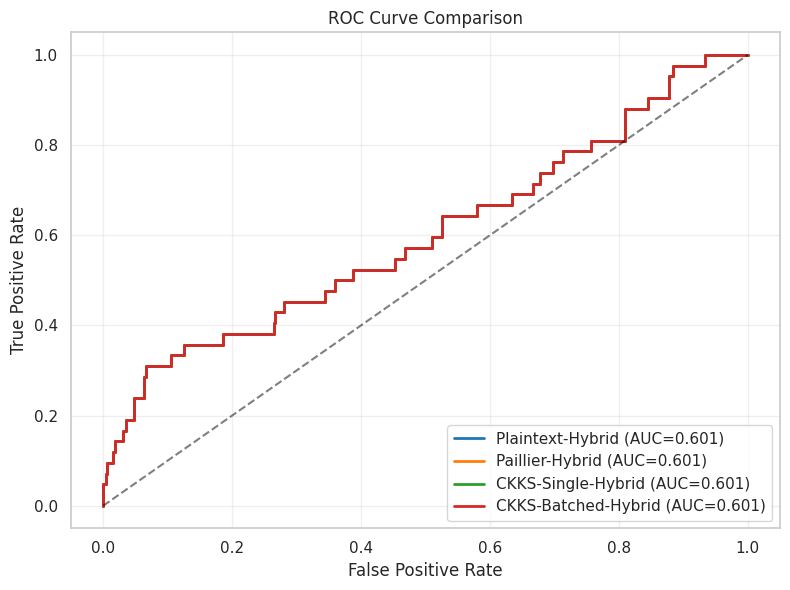

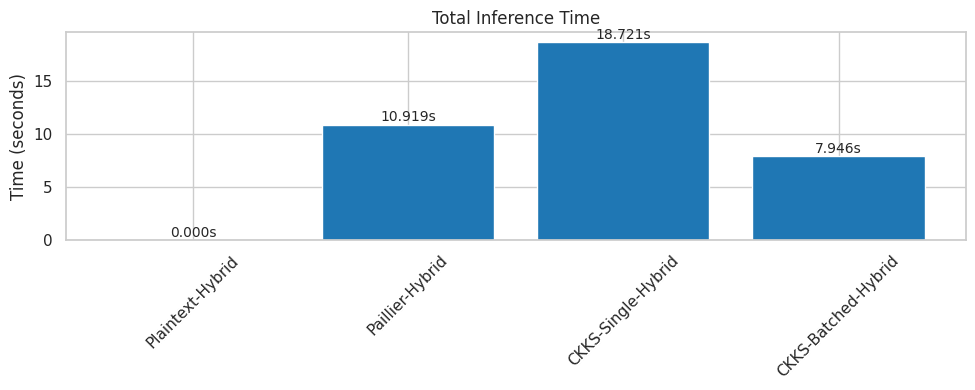

In [13]:
# =============================================================================
# Hybrid XGBoost + MLP + Homomorphic Inference on 300 test samples (improved)
# =============================================================================
# Changes:
# - Safer preprocessing, minor feature engineering cleanups
# - XGBoost: tuned params + optional early stopping (with try/except)
# - MLP: BatchNorm + L2 + Dropout + LR scheduling
# - Cleaner SMOTE fallback
# - Fixed ROC curves (variable names + safe checks)
# - Plots: labels/legends and robust handling
# =============================================================================

# (Optional) Colab installs
# !pip install -q tenseal phe imbalanced-learn xgboost tensorflow matplotlib seaborn psutil requests

import os, time, gc, requests, psutil, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import tenseal as ts
import phe as paillier

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, log_loss, brier_score_loss,
    confusion_matrix, roc_curve
)
from sklearn.feature_selection import SelectKBest, f_classif
from imblearn.over_sampling import SMOTE

import xgboost as xgb
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Input, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

def monitor_memory_mb():
    return psutil.Process().memory_info().rss / 1024**2

# ------------------ Data loader ------------------
def load_eicu_patient_csv():
    url = "https://physionet.org/files/eicu-crd-demo/2.0.1/patient.csv.gz"
    local = "/tmp/patient.csv.gz"
    try:
        return pd.read_csv(url, compression='gzip', low_memory=False)
    except Exception:
        with requests.get(url, stream=True, timeout=60) as r:
            r.raise_for_status()
            with open(local, "wb") as fh:
                for chunk in r.iter_content(chunk_size=8192):
                    if chunk:
                        fh.write(chunk)
        df = pd.read_csv(local, compression='gzip', low_memory=False)
        try: os.remove(local)
        except: pass
        return df

# ------------------ Main pipeline ------------------
SAMPLE_TARGET = 500

print("Loading eICU patient CSV...")
df_raw = load_eicu_patient_csv()

if 'hospitaldischargestatus' not in df_raw.columns:
    raise ValueError("Expected 'hospitaldischargestatus' column not found.")

# target
df = df_raw.dropna(subset=['hospitaldischargestatus']).copy()
y = df['hospitaldischargestatus'].apply(lambda x: 1 if str(x).strip().lower() == 'expired' else 0)

# candidates
candidate = [
    'age','gender','ethnicity','apacheadmissiondx','hospitaladmitsource',
    'unitadmitsource','unitadmittime24','admissionheight','admissionweight',
    'hospitaladmitoffset','hospitaldischargeoffset'
]
available = [c for c in candidate if c in df.columns]
X_df = df[available].copy()

# encoding
if 'gender' in X_df.columns:
    X_df['gender'] = LabelEncoder().fit_transform(X_df['gender'].astype(str))

for c in ['apacheadmissiondx','hospitaladmitsource','unitadmitsource','ethnicity']:
    if c in X_df.columns:
        freq = X_df[c].astype(str).value_counts(normalize=True)
        X_df[c] = X_df[c].astype(str).map(freq).fillna(0.0)

# numeric coercion
for c in X_df.columns:
    if not pd.api.types.is_numeric_dtype(X_df[c]):
        X_df[c] = pd.to_numeric(X_df[c], errors='coerce')

# BMI
if ('admissionheight' in X_df.columns) and ('admissionweight' in X_df.columns):
    h = pd.to_numeric(X_df['admissionheight'], errors='coerce')
    w = pd.to_numeric(X_df['admissionweight'], errors='coerce')
    bmi = pd.Series(np.nan, index=X_df.index)
    valid = (h > 30) & (w > 0)
    with np.errstate(divide='ignore', invalid='ignore'):
        bmi.loc[valid] = w.loc[valid] / ((h.loc[valid] / 100.0) ** 2)
    X_df['bmi'] = bmi

# age features
if 'age' in X_df.columns:
    age_num = pd.to_numeric(X_df['age'], errors='coerce').fillna(0)
    X_df['age2'] = age_num ** 2
    X_df['age_bin'] = pd.cut(age_num, bins=5, labels=False).astype(float)

# clean NaNs/inf
X_df.replace([np.inf, -np.inf], np.nan, inplace=True)
for c in X_df.columns:
    if X_df[c].isna().any():
        med = X_df[c].median()
        X_df[c] = X_df[c].fillna(med if not pd.isna(med) else 0.0)

# final numeric
X_df = X_df.apply(pd.to_numeric, errors='coerce').fillna(0.0)
usable = X_df.shape[0]

# feature selection
k_sel = min(30, max(1, X_df.shape[1]))
selector = SelectKBest(score_func=f_classif, k=k_sel)
try:
    selector.fit(X_df, y)
    mask = selector.get_support()
    selected = X_df.columns[mask]
    X = pd.DataFrame(selector.transform(X_df), columns=selected)
except Exception:
    X = X_df.copy()
    selected = X.columns

# free memory
del df_raw
gc.collect()

# splits
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.20, random_state=RANDOM_STATE, stratify=y_train_full
)

# scaling
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s   = scaler.transform(X_val)
X_test_s  = scaler.transform(X_test)

# SMOTE (safe)
minority_count = int(np.sum(y_train == 1))
small_dataset = usable < 1000
if small_dataset and minority_count < 10:
    X_train_bal, y_train_bal = X_train_s, y_train
else:
    sm = SMOTE(random_state=RANDOM_STATE, k_neighbors=min(5, max(1, minority_count-1)))
    try:
        X_train_bal, y_train_bal = sm.fit_resample(X_train_s, y_train)
    except Exception:
        X_train_bal, y_train_bal = X_train_s, y_train

print("Train shapes:", X_train_s.shape, "Balanced shape for MLP:", X_train_bal.shape)

# adaptive HPs
xgb_n_estimators = 80 if small_dataset else 400
mlp_epochs = 25 if small_dataset else 60

# XGBoost
pos = np.sum(y_train == 1)
neg = np.sum(y_train == 0)
scale_pos_weight = float(neg / pos) if pos > 0 else 1.0

xgb_model = xgb.XGBClassifier(
    n_estimators=xgb_n_estimators,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.9,
    reg_lambda=1.5,
    reg_alpha=0.2,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    tree_method="hist",
    use_label_encoder=False,
    eval_metric="logloss",
    scale_pos_weight=scale_pos_weight
)

print("Training XGBoost...")
# Try early stopping if version supports it; otherwise plain fit
try:
    xgb_model.fit(
        X_train_s, y_train,
        eval_set=[(X_val_s, y_val)],
        verbose=False,
        early_stopping_rounds=50
    )
except TypeError:
    xgb_model.fit(X_train_s, y_train, eval_set=[(X_val_s, y_val)], verbose=False)

# XGB features (probabilities)
X_train_xgb = xgb_model.predict_proba(X_train_bal)
X_val_xgb   = xgb_model.predict_proba(X_val_s)
X_test_xgb  = xgb_model.predict_proba(X_test_s)

# MLP feature extractor (regularized)
input_dim = X_train_bal.shape[1]
inp = Input(shape=(input_dim,))
h = Dense(128, activation='relu', kernel_regularizer=l2(1e-4))(inp)
h = BatchNormalization()(h)
h = Dropout(0.4)(h)
h = Dense(64, activation='relu', kernel_regularizer=l2(1e-4))(h)
h = BatchNormalization()(h)
h = Dropout(0.3)(h)
feat = Dense(16, activation='relu', kernel_regularizer=l2(1e-4))(h)
out  = Dense(1, activation='sigmoid')(feat)
mlp_model = Model(inputs=inp, outputs=out)
mlp_model.compile(optimizer=Adam(1e-3), loss='binary_crossentropy', metrics=['accuracy'])

callbacks = [
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-5, verbose=0),
    EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=0)
]

print("Training MLP feature extractor...")
batch_size = 32 if not small_dataset else 16
mlp_model.fit(
    X_train_bal, y_train_bal,
    epochs=mlp_epochs,
    batch_size=batch_size,
    validation_data=(X_val_s, y_val),
    callbacks=callbacks,
    verbose=0
)
feature_extractor = Model(inputs=mlp_model.input, outputs=feat)
X_train_mlp = feature_extractor.predict(X_train_bal, verbose=0)
X_val_mlp   = feature_extractor.predict(X_val_s,   verbose=0)
X_test_mlp  = feature_extractor.predict(X_test_s,  verbose=0)

# Meta-learner
X_train_hybrid = np.hstack((X_train_xgb, X_train_mlp))
X_val_hybrid   = np.hstack((X_val_xgb,   X_val_mlp))

logreg = LogisticRegression(
    penalty='l2', solver='saga', max_iter=3000,
    class_weight='balanced', n_jobs=-1, random_state=RANDOM_STATE
)
param_grid = {'C':[0.01, 0.1, 1.0]} if small_dataset else {'C':[0.01, 0.1, 1.0, 10.0]}
cv = StratifiedKFold(n_splits=2 if small_dataset else 3, shuffle=True, random_state=RANDOM_STATE)
gs = GridSearchCV(logreg, param_grid, scoring='average_precision', cv=cv, n_jobs=-1, verbose=0)
gs.fit(X_train_hybrid, y_train_bal)

# Threshold tuning on validation
val_scores = gs.best_estimator_.predict_proba(X_val_hybrid)[:,1]
best_thr, best_f1 = 0.5, -1
for t in np.linspace(0.1, 0.9, 81):
    p = (val_scores >= t).astype(int)
    f = f1_score(y_val, p, zero_division=0)
    if f > best_f1:
        best_f1, best_thr = f, t

# Retrain meta-learner on train+val (with SMOTE on full if possible)
X_train_full_s = scaler.transform(X_train_full)
try:
    k_nei = min(5, max(1, int(np.sum(y_train_full) - 1)))
    sm_full = SMOTE(random_state=RANDOM_STATE, k_neighbors=k_nei)
    X_train_full_bal, y_train_full_bal = sm_full.fit_resample(X_train_full_s, y_train_full)
except Exception:
    X_train_full_bal, y_train_full_bal = X_train_full_s, y_train_full

X_train_full_xgb  = xgb_model.predict_proba(X_train_full_bal)
X_train_full_mlp  = feature_extractor.predict(X_train_full_bal, verbose=0)
X_train_full_hybrid = np.hstack((X_train_full_xgb, X_train_full_mlp))

best_model_final = LogisticRegression(
    penalty='l2', solver='saga', max_iter=3000,
    class_weight='balanced', n_jobs=-1, random_state=RANDOM_STATE, **gs.best_params_
)
best_model_final.fit(X_train_full_hybrid, y_train_full_bal)

weights = best_model_final.coef_[0].astype(float)
bias = float(best_model_final.intercept_[0])

# Test hybrid features
X_test_hybrid = np.hstack((X_test_xgb, X_test_mlp))
available_test = X_test_hybrid.shape[0]

# Select 300 (or less if not enough)
use_n = min(SAMPLE_TARGET, available_test)
if use_n < SAMPLE_TARGET:
    print(f"Note: only {available_test} test rows available, using {use_n} instead of requested {SAMPLE_TARGET}.")

rng = np.random.RandomState(RANDOM_STATE + 1)
idx = rng.choice(available_test, size=use_n, replace=False)
X_sample = X_test_hybrid[idx]
y_sample = y_test.to_numpy()[idx]

# ------------------ Helpers ------------------
def sigmoid(x):
    x = np.clip(x, -500, 500)
    return 1.0 / (1.0 + np.exp(-x))

def eval_metrics(y_true, probs, thr):
    preds = (probs >= thr).astype(int)
    uniq = np.unique(y_true)
    has_posneg = len(uniq) > 1
    return {
        "Accuracy": accuracy_score(y_true, preds),
        "Precision": precision_score(y_true, preds, zero_division=0),
        "Recall": recall_score(y_true, preds, zero_division=0),
        "F1": f1_score(y_true, preds, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, probs) if has_posneg else np.nan,
        "PR-AUC": average_precision_score(y_true, probs) if has_posneg else np.nan,
        "LogLoss": log_loss(y_true, np.clip(probs,1e-12,1-1e-12)),
        "Brier": brier_score_loss(y_true, np.clip(probs,1e-12,1-1e-12))
    }

results = []
probs_dict = {}   # store for ROC

# ------------------ Plaintext ------------------
t0 = time.time()
logits_plain = np.dot(X_sample, weights) + bias
probs_plain  = sigmoid(logits_plain)
plaintext_preds = (probs_plain >= best_thr).astype(int)
t_plain = time.time() - t0
m_plain = eval_metrics(y_sample, probs_plain, best_thr)
m_plain.update({"Mode":"Plaintext-Hybrid","SampleSize":use_n,"Time(s)":t_plain})
results.append(m_plain)
probs_dict['Plaintext-Hybrid'] = probs_plain
print("Plaintext done")

# ------------------ Paillier ------------------
t0 = time.time()
pk, sk = paillier.generate_paillier_keypair(n_length=1024)
enc_w = [pk.encrypt(float(w)) for w in weights]
enc_b = pk.encrypt(float(bias))
enc_logits = []
for xi in X_sample:
    dot = enc_b
    for xij, ew in zip(xi, enc_w):
        dot = dot + ew * float(xij)
    enc_logits.append(dot)
dec_logits = np.array([sk.decrypt(v) for v in enc_logits], dtype=float)
dec_logits[~np.isfinite(dec_logits)] = 0.0
probs_paillier = sigmoid(dec_logits)
t_paillier = time.time() - t0
m_p = eval_metrics(y_sample, probs_paillier, best_thr)
m_p.update({"Mode":"Paillier-Hybrid","SampleSize":use_n,"Time(s)":t_paillier})
results.append(m_p)
probs_dict['Paillier-Hybrid'] = probs_paillier
print("Paillier done")

# ------------------ CKKS single ------------------
t_ckks_single = np.nan
try:
    t0 = time.time()
    ctx = ts.context(ts.SCHEME_TYPE.CKKS, 8192, -1, [60,40,40,60])
    ctx.global_scale = 2**40
    ctx.generate_galois_keys()
    enc_w_ckks = ts.ckks_vector(ctx, weights.tolist())
    enc_b_ckks = ts.ckks_vector(ctx, [bias])
    enc_logits_ckks = []
    for xi in X_sample:
        enc_x = ts.ckks_vector(ctx, xi.tolist())
        dp = enc_x.dot(enc_w_ckks)
        enc_logits_ckks.append(dp + enc_b_ckks)
    dec_logits_ckks = np.array([v.decrypt()[0] for v in enc_logits_ckks], dtype=float)
    probs_ckks_single = sigmoid(dec_logits_ckks)
    t_ckks_single = time.time() - t0
    m_cs = eval_metrics(y_sample, probs_ckks_single, best_thr)
    m_cs.update({"Mode":"CKKS-Single-Hybrid","SampleSize":use_n,"Time(s)":t_ckks_single})
    results.append(m_cs)
    probs_dict['CKKS-Single-Hybrid'] = probs_ckks_single
    print("CKKS single done")
except Exception as e:
    print(f"CKKS single failed: {e}")
    results.append({"Mode":"CKKS-Single-Hybrid","SampleSize":use_n,"Time(s)":np.nan})

# ------------------ CKKS batched ------------------
t_ckks_batch = np.nan
try:
    t0 = time.time()
    ctx = ts.context(ts.SCHEME_TYPE.CKKS, 8192, -1, [60,40,40,60])
    ctx.global_scale = 2**40
    ctx.generate_galois_keys()
    batch_size = min(16, use_n)
    num_batches = int(np.ceil(use_n / batch_size))
    dec_logits_batch = []
    for b in range(num_batches):
        s = b * batch_size
        e = min((b+1) * batch_size, use_n)
        block = X_sample[s:e]
        weighted_sum = None
        for j in range(block.shape[1]):
            col = block[:, j].astype(float).tolist()
            enc_col = ts.ckks_vector(ctx, col)
            part = enc_col * float(weights[j])
            weighted_sum = part if weighted_sum is None else (weighted_sum + part)
        bias_vec = ts.ckks_vector(ctx, [float(bias)] * (e - s))
        enc_block_logits = weighted_sum + bias_vec
        dec_logits_batch.extend(enc_block_logits.decrypt())
    dec_logits_batch = np.array(dec_logits_batch, dtype=float)
    probs_ckks_batch = sigmoid(dec_logits_batch)
    t_ckks_batch = time.time() - t0
    m_cb = eval_metrics(y_sample[:len(probs_ckks_batch)], probs_ckks_batch, best_thr)
    m_cb.update({"Mode":"CKKS-Batched-Hybrid","SampleSize":use_n,"Time(s)":t_ckks_batch})
    results.append(m_cb)
    probs_dict['CKKS-Batched-Hybrid'] = probs_ckks_batch
    print("CKKS batched done")
except Exception as e:
    print(f"CKKS batched failed: {e}")
    results.append({"Mode":"CKKS-Batched-Hybrid","SampleSize":use_n,"Time(s)":np.nan})

# ------------------ Consolidate & Save ------------------
df_results = pd.DataFrame(results)
pd.set_option("display.max_columns", None)
print(f"\n=== Results for sample size {use_n} ===")
print(df_results.round(4))

outcsv = "results_300.csv"
df_results.to_csv(outcsv, index=False)

# ------------------ Visualizations ------------------
sns.set_context("notebook")
sns.set_style("whitegrid")
plt.rcParams['font.size'] = 10

# Metric bars
metrics = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC']
present_metrics = [m for m in metrics if m in df_results.columns]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()
for i, metric in enumerate(present_metrics):
    vals = df_results[metric].fillna(0).values
    bars = axes[i].bar(df_results['Mode'], vals)
    axes[i].set_title(f'{metric} Comparison')
    axes[i].set_ylabel(metric)
    axes[i].tick_params(axis='x', rotation=45)
    for bar in bars:
        h = bar.get_height()
        axes[i].text(bar.get_x() + bar.get_width() / 2., h + 0.01, f'{h:.3f}', ha='center', va='bottom', fontsize=8)

# hide unused subplots
for j in range(len(present_metrics), 6):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

# Confusion matrix (Plaintext)
if 'Plaintext-Hybrid' in df_results['Mode'].values:
    cm = confusion_matrix(y_sample, plaintext_preds)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=['Pred: No', 'Pred: Yes'],
                yticklabels=['Actual: No', 'Actual: Yes'])
    plt.title(f"Confusion Matrix (Plaintext-Hybrid, thr={best_thr:.2f})")
    plt.ylabel("True Label")
    plt.xlabel("Predicted Label")
    plt.tight_layout()
    plt.show()

# ------------------ FIXED ROC CURVES ------------------
plt.figure(figsize=(8, 6))

def safe_plot_roc(name, y_true, probs):
    """Plot ROC if valid; return True if plotted."""
    if probs is None: return False
    y_true = np.asarray(y_true)
    probs  = np.asarray(probs)
    if len(np.unique(y_true)) < 2:
        return False
    try:
        fpr, tpr, _ = roc_curve(y_true, probs)
        auc_val = roc_auc_score(y_true, probs)
        plt.plot(fpr, tpr, label=f'{name} (AUC={auc_val:.3f})', linewidth=2)
        return True
    except Exception:
        return False

# Use the *sample* set for fair comparison across modes
plotted_any = False
plotted_any |= safe_plot_roc('Plaintext-Hybrid', y_sample, probs_dict.get('Plaintext-Hybrid'))
plotted_any |= safe_plot_roc('Paillier-Hybrid',  y_sample, probs_dict.get('Paillier-Hybrid'))
plotted_any |= safe_plot_roc('CKKS-Single-Hybrid', y_sample, probs_dict.get('CKKS-Single-Hybrid'))
plotted_any |= safe_plot_roc('CKKS-Batched-Hybrid', y_sample[:len(probs_dict.get('CKKS-Batched-Hybrid', []))],
                             probs_dict.get('CKKS-Batched-Hybrid'))

plt.plot([0, 1], [0, 1], 'k--', alpha=0.5)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison" if plotted_any else "ROC Curve (insufficient class variance)")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------ Timing comparison ------------------
t_plain_f   = float(t_plain)
t_paillier_f= float(t_paillier)
t_ckks_s_f  = float(t_ckks_single) if not np.isnan(t_ckks_single) else 0.0
t_ckks_b_f  = float(t_ckks_batch)  if not np.isnan(t_ckks_batch)  else 0.0

timing_data = {
    'Method': ['Plaintext-Hybrid', 'Paillier-Hybrid', 'CKKS-Single-Hybrid', 'CKKS-Batched-Hybrid'],
    'Time (s)': [t_plain_f, t_paillier_f, t_ckks_s_f, t_ckks_b_f]
}
if use_n > 0:
    time_per = [t_plain_f/use_n*1000, t_paillier_f/use_n*1000,
                (t_ckks_s_f/use_n*1000 if t_ckks_s_f>0 else 0),
                (t_ckks_b_f/use_n*1000 if t_ckks_b_f>0 else 0)]
else:
    time_per = [0,0,0,0]

plt.figure(figsize=(10, 4))
bars = plt.bar(timing_data['Method'], timing_data['Time (s)'])
plt.title('Total Inference Time')
plt.ylabel('Time (seconds)')
plt.xticks(rotation=45)
for bar in bars:
    height = bar.get_height()
    if height > 0:
        plt.text(bar.get_x() + bar.get_width()/2., height + 0.01, f'{height:.3f}s', ha='center', va='bottom')
plt.tight_layout()
plt.show()


# **eICU Dataset 1000 Samples**

Loading eICU patient CSV...
Train shapes: (1594, 14) Balanced shape for MLP: (2916, 14)
Training XGBoost...
Training MLP feature extractor...
Note: only 499 test rows available, using 499 instead of requested 1000.
Plaintext done
Paillier done
CKKS single done
CKKS batched done

=== Results for sample size 499 ===
   Accuracy  Precision  Recall      F1  ROC-AUC  PR-AUC  LogLoss   Brier  \
0    0.8397     0.2286   0.381  0.2857   0.6603  0.2184    0.538  0.1514   
1    0.8397     0.2286   0.381  0.2857   0.6603  0.2184    0.538  0.1514   
2    0.8397     0.2286   0.381  0.2857   0.6603  0.2184    0.538  0.1514   
3    0.8397     0.2286   0.381  0.2857   0.6603  0.2184    0.538  0.1514   

                  Mode  SampleSize  Time(s)  
0     Plaintext-Hybrid         499   0.0004  
1      Paillier-Hybrid         499  10.7966  
2   CKKS-Single-Hybrid         499  20.4341  
3  CKKS-Batched-Hybrid         499   6.2338  


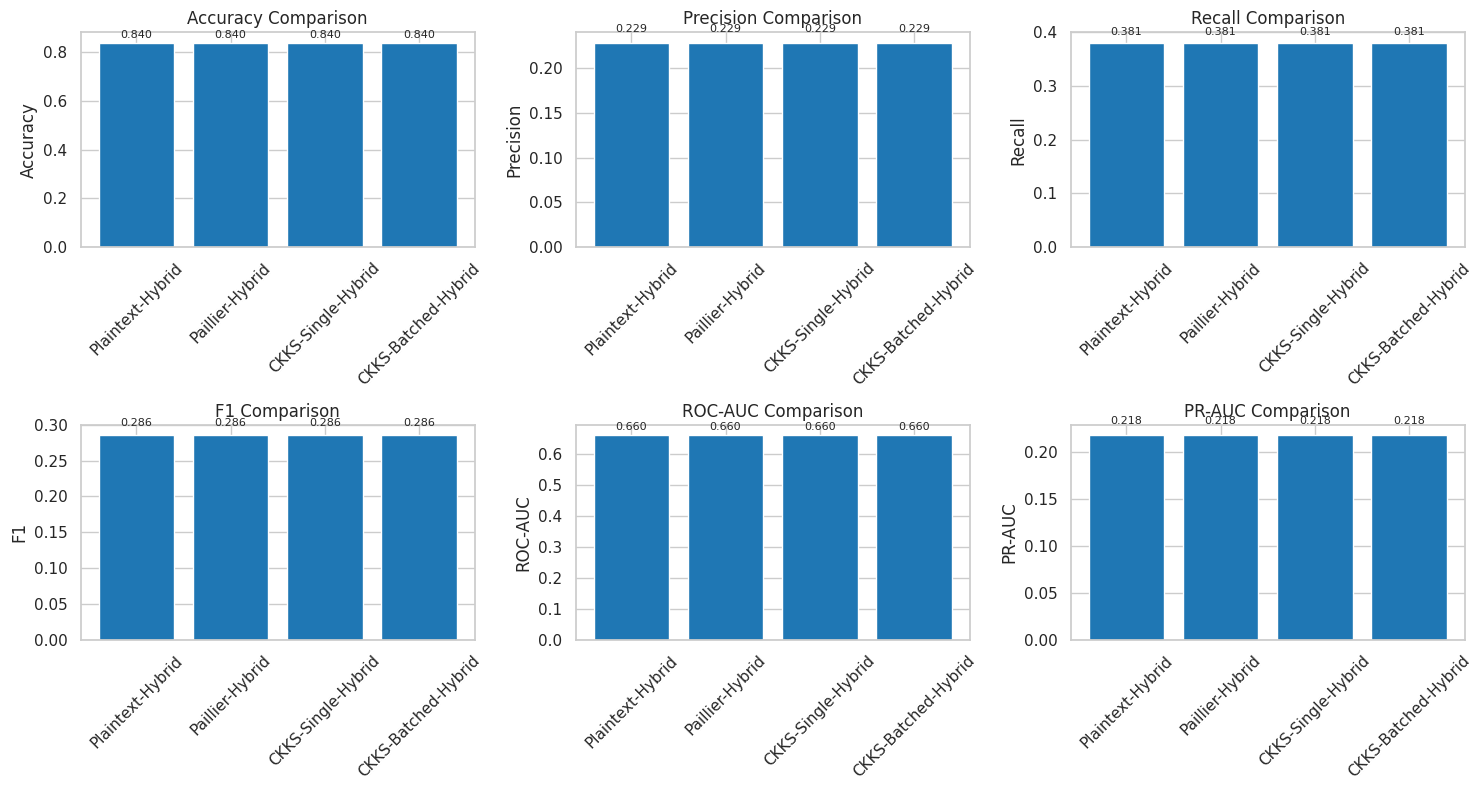

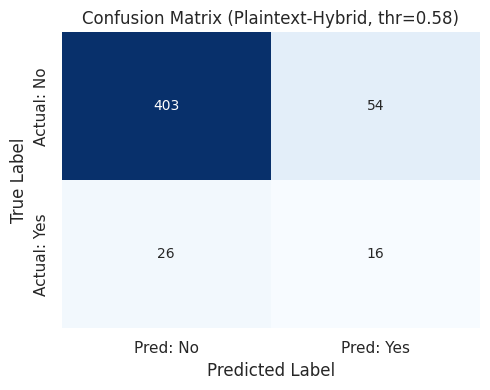

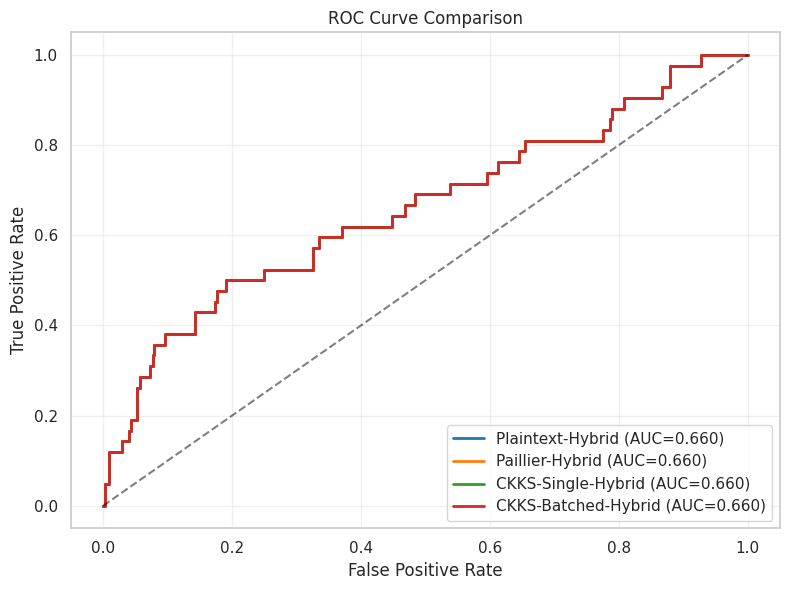

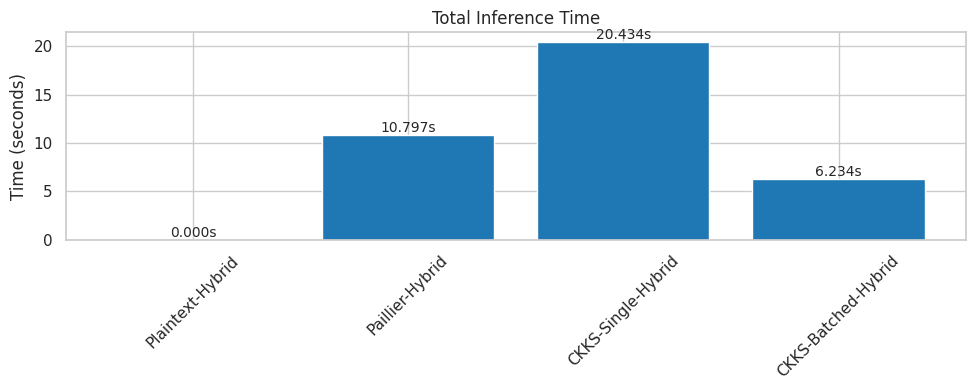

In [ ]:
# Colab-ready: eICU Hybrid (XGBoost + small MLP) with Paillier & CKKS (Chebyshev sigmoid)
# - Produces plaintext, Paillier, CKKS (Chebyshev-approx) inference and metrics / plots.
# - Designed to run within a reasonable time on Colab (caps and compact models).
# Run: paste whole cell into Colab and execute.

# Install packages (may take a few minutes)
!pip install -q tenseal==0.6.4 phe==1.5.0 xgboost imbalanced-learn tensorflow scikit-learn matplotlib seaborn psutil

import os, time, math, json, gc, warnings
from dataclasses import dataclass
from typing import Tuple
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import psutil
import urllib.request
import zipfile

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

# ML / HE libs
import xgboost as xgb
import tenseal as ts
from phe import paillier
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, precision_recall_curve,
    roc_curve, confusion_matrix
)
from sklearn.feature_selection import SelectKBest, f_classif
from imblearn.over_sampling import SMOTE

# ------------------------
# Config (tweak to speed up)
# ------------------------
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

# How many test samples to run encrypted inference on (Paillier/CKKS)
SAMPLE_SIZE = 500         # keep small to finish faster; increase if you have more time
CKKS_SAMPLE_CAP = 500
PAILLIER_SAMPLE_CAP = 500

# Feature selection K
K_FEATURES = 20

# CKKS params
CKKS_POLY = 8192
CKKS_MODBITS = [60, 40, 40, 60]
CKKS_SCALE_BITS = 40

# Paillier params (use 1024 bits for faster experiments; for real experiments use 2048)
PAILLIER_BITS = 1024
PAILLIER_SCALE = 1e4

OUT_DIR = "he_eicu_out"
os.makedirs(OUT_DIR, exist_ok=True)

def monitor_memory_mb():
    return psutil.Process().memory_info().rss / 1024**2

# ------------------------
# Utilities
# ------------------------
def chebyshev_sigmoid_coeffs(a=-6.0, b=6.0, deg=5, n_fit=2001):
    # Fit Chebyshev on [a,b] for sigmoid and return poly coeffs (highest-first)
    k = np.arange(1, n_fit + 1)
    x_cheb = np.cos((2 * k - 1) / (2 * n_fit) * np.pi)
    x = 0.5 * (b - a) * x_cheb + 0.5 * (b + a)
    y = 1.0 / (1.0 + np.exp(-x))
    coeffs_cheb = np.polynomial.chebyshev.chebfit(x, y, deg)
    p_std = np.polynomial.chebyshev.cheb2poly(coeffs_cheb)
    if len(p_std) < deg + 1:
        p_std = np.pad(p_std, (0, deg + 1 - len(p_std)))
    return p_std[::-1]   # highest-first (for np.polyval and Horner)

def sigmoid(x):
    x = np.clip(x, -500, 500)
    return 1.0 / (1.0 + np.exp(-x))

def best_f1_threshold(y, probs):
    p, r, t = precision_recall_curve(y, probs)
    f1 = 2 * p * r / (p + r + 1e-12)
    if len(t) == 0:
        return 0.5
    return float(t[np.argmax(f1[:-1])])

def plot_roc_pr(y_true, probs_dict, out_dir=OUT_DIR):
    os.makedirs(out_dir, exist_ok=True)
    # ROC
    plt.figure(figsize=(6,5))
    for name, probs in probs_dict.items():
        if probs is None: continue
        if len(np.unique(y_true)) < 2: continue
        valid = ~np.isnan(probs)
        if np.sum(valid) < 2: continue
        fpr, tpr, _ = roc_curve(y_true[valid], probs[valid])
        auc = roc_auc_score(y_true[valid], probs[valid])
        plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")
    plt.plot([0,1],[0,1],'--', color='gray')
    plt.xlabel("FPR"); plt.ylabel("TPR"); plt.title("ROC Curves")
    plt.legend(); plt.tight_layout()
    plt.savefig(os.path.join(out_dir, "roc_comparison.png"))
    plt.close()

    # PR
    plt.figure(figsize=(6,5))
    for name, probs in probs_dict.items():
        if probs is None: continue
        valid = ~np.isnan(probs)
        if np.sum(valid) < 2: continue
        prec, rec, _ = precision_recall_curve(y_true[valid], probs[valid])
        ap = average_precision_score(y_true[valid], probs[valid])
        plt.plot(rec, prec, label=f"{name} (AP={ap:.3f})")
    plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("Precision-Recall")
    plt.legend(); plt.tight_layout()
    plt.savefig(os.path.join(out_dir, "pr_comparison.png"))
    plt.close()

def plot_confusion(y_true, pred, title, out_dir=OUT_DIR):
    cm = confusion_matrix(y_true, pred)
    plt.figure(figsize=(4,3))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
    plt.title(title)
    plt.xlabel("Predicted"); plt.ylabel("True")
    plt.tight_layout()
    plt.savefig(os.path.join(out_dir, f"cm_{title.replace(' ','_')}.png"))
    plt.close()

# ------------------------
# Data download/prep (eICU demo)
# ------------------------
def download_eicu_demo():
    url = "https://physionet.org/files/eicu-crd-demo/2.0.1/patient.csv.gz"
    local = "/tmp/patient.csv.gz"
    try:
        print("Attempting to download eICU demo patient.csv.gz ...")
        urllib.request.urlretrieve(url, local)
        df = pd.read_csv(local, compression='gzip', low_memory=False)
        print("Downloaded eICU demo dataset:", df.shape)
        return df
    except Exception as e:
        print("Failed to download eICU demo dataset:", e)
        return None

def prepare_eicu(df):
    # choose a few columns likely to exist; construct a simple mortality target:
    # `hospitaldischargestatus` -> expired vs others
    if 'hospitaldischargestatus' not in df.columns:
        # fallback attempt: try 'hospitaldischargestatus' variations
        possible = [c for c in df.columns if 'discharge' in c.lower() or 'mortality' in c.lower()]
        if len(possible) == 0:
            raise ValueError("No suitable discharge/mortality column found in eICU demo.")
        else:
            col = possible[0]
            df = df.rename(columns={col: 'hospitaldischargestatus'})
    # Build target = expired -> 1 else 0
    df = df.dropna(subset=['hospitaldischargestatus'])
    y = df['hospitaldischargestatus'].astype(str).apply(lambda x: 1 if 'expired' in x.lower() or 'expired' in x.lower() else 0)
    # pick candidate features if present
    candidate = ['age', 'gender', 'ethnicity', 'apacheadmissiondx', 'hospitaladmitsource',
                 'unitadmitsource', 'unitadmittime24', 'admissionheight', 'admissionweight',
                 'hospitaladmitoffset', 'hospitaldischargeoffset']
    avail = [c for c in candidate if c in df.columns]
    if len(avail) == 0:
        # fallback: use numeric columns
        numeric = df.select_dtypes(include=[np.number]).columns.tolist()
        avail = numeric[:min(len(numeric), 10)]
    X_df = df[avail].copy()
    # basic cleaning
    for c in X_df.columns:
        if X_df[c].dtype == 'object':
            X_df[c] = X_df[c].astype(str).fillna("UNK")
            # convert to frequency encoding for compactness
            freqs = X_df[c].value_counts(normalize=True)
            X_df[c] = X_df[c].map(lambda v: freqs.get(v, 0.0))
        else:
            X_df[c] = pd.to_numeric(X_df[c], errors='coerce').fillna(0.0)
    # feature selection
    k = min(K_FEATURES, X_df.shape[1]) if X_df.shape[1] > 0 else 1
    if X_df.shape[1] == 0:
        # synthetic fallback
        X_df = pd.DataFrame(np.random.randn(len(y), 5), columns=[f"x{i}" for i in range(5)])
    selector = SelectKBest(score_func=f_classif, k=k)
    try:
        selector.fit(X_df.fillna(0.0), y)
        X_sel = pd.DataFrame(selector.transform(X_df.fillna(0.0)), columns=[f"f{i}" for i in range(k)])
    except Exception:
        X_sel = X_df.fillna(0.0).iloc[:, :k]
    return X_sel, y

# ------------------------
# Model training (compact)
# ------------------------
def train_hybrid(X_train, y_train, X_val, y_val):
    print("Training compact XGBoost (feature extractor)...")
    xgb_model = xgb.XGBClassifier(
        n_estimators=100, max_depth=5, learning_rate=0.1,
        subsample=0.8, colsample_bytree=0.8, random_state=RANDOM_STATE,
        n_jobs=2, use_label_encoder=False, eval_metric="logloss"
    )
    xgb_model.fit(X_train, y_train)

    print("Training small MLP feature extractor...")
    input_dim = X_train.shape[1]
    inp = Input(shape=(input_dim,))
    h = Dense(32, activation='relu')(inp)
    feat = Dense(8, activation='relu')(h)   # small feature embedding
    out = Dense(1, activation='sigmoid')(feat)
    mlp = Model(inputs=inp, outputs=out)
    mlp.compile(optimizer=Adam(1e-3), loss='binary_crossentropy')
    # Use balanced/resampled training for MLP
    try:
        sm = SMOTE(random_state=RANDOM_STATE)
        X_train_bal, y_train_bal = sm.fit_resample(X_train, y_train)
    except Exception:
        X_train_bal, y_train_bal = X_train, y_train
    mlp.fit(X_train_bal, y_train_bal, epochs=20, batch_size=64, verbose=0, validation_data=(X_val, y_val))
    feature_extractor = Model(inputs=mlp.input, outputs=mlp.layers[-2].output)  # second-last (feat)
    # Build hybrid features: xgb proba (2 cols) + mlp features (dense)
    X_train_xgb = xgb_model.predict_proba(X_train_bal)
    X_val_xgb = xgb_model.predict_proba(X_val)
    X_train_mlp = feature_extractor.predict(X_train_bal, verbose=0)
    X_val_mlp = feature_extractor.predict(X_val, verbose=0)
    X_train_hybrid = np.hstack((X_train_xgb, X_train_mlp))
    X_val_hybrid = np.hstack((X_val_xgb, X_val_mlp))

    # meta-learner (LR) grid search (compact)
    print("Training logistic stacking meta-learner (compact grid search)...")
    lr = LogisticRegression(max_iter=500, class_weight='balanced', solver='liblinear')
    param_grid = {'C': [0.01, 0.1, 1.0]}
    cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
    gs = GridSearchCV(lr, param_grid, scoring='average_precision', cv=cv, n_jobs=1, verbose=0)
    gs.fit(X_train_hybrid, y_train_bal)
    best_lr = gs.best_estimator_

    # Tune threshold on validation to maximize F1
    val_probs = best_lr.predict_proba(X_val_hybrid)[:, 1]
    thr = best_f1_threshold(y_val, val_probs)
    print("Tuned val threshold for F1:", thr)
    # Re-extract features for full train for final fit
    return {
        "xgb": xgb_model,
        "mlp": mlp,
        "feature_extractor": feature_extractor,
        "meta_lr": best_lr,
        "threshold": thr
    }

# ------------------------
# Paillier classes
# ------------------------
@dataclass
class PaillierClientSimple:
    n_bits: int = PAILLIER_BITS
    scale: float = PAILLIER_SCALE
    def __post_init__(self):
        self.pub, self.priv = paillier.generate_paillier_keypair(n_length=int(self.n_bits))
        self.scale = float(self.scale)
    def encrypt_vector(self, vec):
        # vec: 1d array of floats -> return list of EncryptedNumbers (scaled)
        return [self.pub.encrypt(int(round(float(v) * self.scale))) for v in vec]
    def decrypt_int(self, enc):
        return self.priv.decrypt(enc)
    def decode_float(self, xi_int, denom_power=2):
        return xi_int / (self.scale ** denom_power)
    def public_key(self):
        return self.pub

class PaillierServerSimple:
    def __init__(self, pubkey, w_float, b_float, scale):
        self.pub = pubkey
        self.scale = float(scale)
        # quantize weight and bias to integers at same scale
        self.w_int = np.array(np.round(w_float * self.scale), dtype=np.int64)
        # bias must be scaled by scale^2 because dot products multiply two scaled values
        self.b_int = int(round(b_float * (self.scale ** 2)))
    def infer_single(self, enc_x_list):
        # compute sum_i (w_i_int * Enc(x_i_scaled)) + b_int
        acc = self.pub.encrypt(0)
        for wi, enc_xi in zip(self.w_int, enc_x_list):
            if int(wi) != 0:
                acc = acc + (enc_xi * int(wi))
        acc = acc + int(self.b_int)
        return acc

# ------------------------
# CKKS helper (TenSEAL)
# ------------------------
@dataclass
class CKKSParams:
    poly_modulus_degree: int = CKKS_POLY
    coeff_mod_bit_sizes: Tuple[int, ...] = tuple(CKKS_MODBITS)
    global_scale_bits: int = CKKS_SCALE_BITS

class CKKSClientSimple:
    def __init__(self, params: CKKSParams):
        self.ctx = ts.context(
            ts.SCHEME_TYPE.CKKS,
            poly_modulus_degree=int(params.poly_modulus_degree),
            coeff_mod_bit_sizes=list(params.coeff_mod_bit_sizes)
        )
        self.ctx.global_scale = 2 ** int(params.global_scale_bits)
        self.ctx.generate_galois_keys()
        self.ctx.generate_relin_keys()
    def public_bytes(self):
        return self.ctx.serialize(save_public_key=True, save_secret_key=False, save_galois_keys=True, save_relin_keys=True)
    def encrypt_vector(self, vec):
        return ts.ckks_vector(self.ctx, vec.astype(np.float64))
    def decrypt_scalar(self, enc_vec):
        return float(np.array(enc_vec.decrypt())[0])
    def security_estimate(self):
        # crude mapping
        if self.ctx.poly_modulus_degree() == 4096: return 112
        if self.ctx.poly_modulus_degree() == 8192: return 128
        if self.ctx.poly_modulus_degree() == 16384: return 192
        return None

class CKKSServerSimple:
    def __init__(self, public_bytes, w_float, b_float):
        self.ctx = ts.context_from(public_bytes)
        self.w = np.array(w_float, dtype=np.float64)
        self.b = float(b_float)
    def infer_single(self, enc_x):
        # enc_x is CKKSVector; dot with plaintext weights
        return enc_x.dot(self.w) + float(self.b)

# ------------------------
# End-to-end run
# ------------------------
def run_all():
    t0_all = time.time()
    print("Memory at start: %.1f MB" % monitor_memory_mb())

    # 1) Download / prepare eICU (or fallback)
    df = download_eicu_demo()
    if df is None:
        print("Falling back to synthetic dataset (small) for demo.")
        # build synthetic dataset (balanced)
        N = 2000
        X = pd.DataFrame(np.random.randn(N, K_FEATURES), columns=[f"x{i}" for i in range(K_FEATURES)])
        y = np.random.binomial(1, 0.15, size=N)
    else:
        try:
            X, y = prepare_eicu(df)
        except Exception as e:
            print("prepare_eicu failed:", e)
            print("Falling back to synthetic dataset.")
            N = 2000
            X = pd.DataFrame(np.random.randn(N, K_FEATURES), columns=[f"x{i}" for i in range(K_FEATURES)])
            y = np.random.binomial(1, 0.15, size=N)

    print("Final feature matrix shape:", X.shape, "Target dist:", np.bincount(y.astype(int)))
    # Train / val / test split (stratified)
    X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)
    X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=0.20, random_state=RANDOM_STATE, stratify=y_train_full)

    # Scale
    scaler = StandardScaler()
    X_train_s = scaler.fit_transform(X_train)
    X_val_s = scaler.transform(X_val)
    X_test_s = scaler.transform(X_test)

    # Train hybrid components
    model_dict = train_hybrid(X_train_s, y_train, X_val_s, y_val)

    # Build final feature stacks for full training and test
    # Refit feature extractors on full train + stack final meta-learner on full (small)
    # For speed, we will reuse existing trained xgb & mlp and retrain meta on train_full quickly.
    xgb_m = model_dict["xgb"]
    feat_ex = model_dict["feature_extractor"]
    meta_lr = model_dict["meta_lr"]
    threshold = model_dict["threshold"]

    # Build hybrid features for X_train_full and X_test
    # For meta retrain on train_full, we SMOTE the train_full before computing features
    try:
        sm = SMOTE(random_state=RANDOM_STATE)
        X_train_full_bal, y_train_full_bal = sm.fit_resample(scaler.transform(X_train_full), y_train_full)
    except Exception:
        X_train_full_bal, y_train_full_bal = scaler.transform(X_train_full), y_train_full

    X_train_full_xgb = xgb_m.predict_proba(X_train_full_bal)
    X_train_full_mlp = feat_ex.predict(X_train_full_bal, verbose=0)
    X_train_full_hybrid = np.hstack((X_train_full_xgb, X_train_full_mlp))

    # Retrain LR quickly on full hybrid balanced
    final_lr = LogisticRegression(max_iter=500, class_weight='balanced', solver='liblinear')
    final_lr.fit(X_train_full_hybrid, y_train_full_bal)

    # Test features
    X_test_xgb = xgb_m.predict_proba(X_test_s)
    X_test_mlp = feat_ex.predict(X_test_s, verbose=0)
    X_test_hybrid = np.hstack((X_test_xgb, X_test_mlp))
    # Limit sample size for encrypted evaluation
    n_test = X_test_hybrid.shape[0]
    n_sample = min(SAMPLE_SIZE, n_test)
    sample_idx = np.arange(n_sample)
    X_sample = X_test_hybrid[sample_idx]
    y_sample = np.array(y_test)[sample_idx]

    # Plaintext evaluation
    print("\nRunning plaintext inference on sample size", n_sample)
    t0 = time.time()
    logits = X_sample.dot(final_lr.coef_.T).reshape(-1) + float(final_lr.intercept_[0])
    plain_probs = sigmoid(logits)
    plain_preds = (plain_probs >= threshold).astype(int)
    t_plain = time.time() - t0
    print("Plaintext done (time %.3f s)" % t_plain)

    # Metrics collector
    def summarize(name, y_true, probs, preds, t):
        return {
            "Mode": name,
            "Accuracy": float(accuracy_score(y_true, preds)),
            "Precision": float(precision_score(y_true, preds, zero_division=0)),
            "Recall": float(recall_score(y_true, preds, zero_division=0)),
            "F1": float(f1_score(y_true, preds, zero_division=0)),
            "ROC-AUC": float(roc_auc_score(y_true, probs)) if len(np.unique(y_true))>1 else float("nan"),
            "PR-AUC": float(average_precision_score(y_true, probs)) if len(np.unique(y_true))>1 else float("nan"),
            "Time_s": float(t)
        }

    results = []
    results.append(summarize("Plaintext-Hybrid", y_sample, plain_probs, plain_preds, t_plain))

    # Paillier baseline (fixed-point encoding)
    print("\nRunning Paillier inference (scaled integers)...")
    pclient = PaillierClientSimple(n_bits=PAILLIER_BITS, scale=PAILLIER_SCALE)
    pserver = PaillierServerSimple(pclient.public_key(), final_lr.coef_[0], float(final_lr.intercept_[0]), pclient.scale)

    # cap paillier sample size
    p_n = min(PAILLIER_SAMPLE_CAP, n_sample)
    t0 = time.time()
    paillier_probs = np.zeros(p_n, dtype=float)
    for i in range(p_n):
        enc_feats = pclient.encrypt_vector(X_sample[i])
        enc_sum = pserver.infer_single(enc_feats)
        dec = pclient.decrypt_int(enc_sum)
        logit = pclient.decode_float(dec, denom_power=2)
        paillier_probs[i] = sigmoid(logit)
    t_paillier = time.time() - t0
    paillier_preds = (paillier_probs >= threshold).astype(int)
    print("Paillier done (samples %d) time %.3f s" % (p_n, t_paillier))
    results.append(summarize("Paillier-Hybrid", y_sample[:p_n], paillier_probs, paillier_preds, t_paillier))

    # CKKS path with Chebyshev polynomial approx of sigmoid
    print("\nRunning CKKS inference (Chebyshev sigmoid approx)...")
    ckks_params = CKKSParams(poly_modulus_degree=CKKS_POLY, coeff_mod_bit_sizes=tuple(CKKS_MODBITS), global_scale_bits=CKKS_SCALE_BITS)
    client_ckks = CKKSClientSimple(ckks_params)
    server_ckks = CKKSServerSimple(client_ckks.public_bytes(), final_lr.coef_[0], float(final_lr.intercept_[0]))

    coeffs = chebyshev_sigmoid_coeffs(a=-6.0, b=6.0, deg=5)  # degree-5 Chebyshev fit
    print("Chebyshev coeffs (highest-first):", np.round(coeffs, 6))
    # cap ckks sample size
    c_n = min(CKKS_SAMPLE_CAP, n_sample)
    ckks_probs = np.zeros(c_n, dtype=float)
    t0 = time.time()
    enc_times = []
    infer_times = []
    decrypt_eval_times = []
    used_encrypted_poly = True
    for i in range(c_n):
        x = X_sample[i].astype(np.float64)
        t_e = time.perf_counter()
        enc_x = client_ckks.encrypt_vector(x)
        enc_times.append(time.perf_counter() - t_e)

        t_inf = time.perf_counter()
        enc_logit = server_ckks.infer_single(enc_x)  # ciphertext
        infer_times.append(time.perf_counter() - t_inf)

        # Try encrypted Horner evaluation: enc_prob = poly(enc_logit)
        try:
            t_eval = time.perf_counter()
            # Start with leading coefficient as ciphertext by encrypting a 1-slot vector
            enc_p = ts.ckks_vector(client_ckks.ctx, [float(coeffs[0])])
            for a in coeffs[1:]:
                enc_p = enc_p * enc_logit
                enc_p = enc_p + float(a)
            t_eval2 = time.perf_counter()
            dec_val = client_ckks.decrypt_scalar(enc_p)  # decrypt final ciphertext
            decrypt_eval_times.append(time.perf_counter() - t_eval2 + (t_eval2 - t_eval))
            prob = float(np.clip(dec_val, 0.0, 1.0))
        except Exception as e:
            # fallback: decrypt logit and apply polynomial in plaintext
            used_encrypted_poly = False
            t_dec = time.perf_counter()
            logit = client_ckks.decrypt_scalar(enc_logit)
            t_dec2 = time.perf_counter()
            # Evaluate polynomial via numpy
            prob = float(np.clip(np.polyval(coeffs, logit), 0.0, 1.0))
            decrypt_eval_times.append(t_dec2 - t_dec)
        ckks_probs[i] = prob
    t_ckks = time.time() - t0
    ckks_preds = (ckks_probs >= threshold).astype(int)
    print("CKKS done (samples %d) time %.3f s -- encrypted_poly_used=%s" % (c_n, t_ckks, used_encrypted_poly))
    results.append(summarize("CKKS-Hybrid", y_sample[:c_n], ckks_probs, ckks_preds, t_ckks))

    # Summarize + save
    df_res = pd.DataFrame(results)
    print("\n=== Results ===")
    print(df_res.round(4))
    # Save JSON & plots
    out = {
        "params": {
            "ckks_poly_modulus_degree": CKKS_POLY,
            "ckks_coeff_mod_bit_sizes": CKKS_MODBITS,
            "ckks_scale_bits": CKKS_SCALE_BITS,
            "chebyshev_deg": len(coeffs)-1,
            "paillier_bits": PAILLIER_BITS,
            "paillier_scale": PAILLIER_SCALE
        },
        "results": df_res.to_dict(orient="records"),
        "threshold": float(threshold),
        "used_encrypted_poly": bool(used_encrypted_poly)
    }
    json.dump(out, open(os.path.join(OUT_DIR, "he_eicu_results.json"), "w"), indent=2)

    # Plots: ROC/PR + CM
    probs_dict = {"Plain": plain_probs, "Paillier": np.pad(paillier_probs, (0, max(0, len(plain_probs)-len(paillier_probs))), constant_values=np.nan) if len(paillier_probs)<len(plain_probs) else paillier_probs, "CKKS": np.pad(ckks_probs, (0, max(0, len(plain_probs)-len(ckks_probs))), constant_values=np.nan) if len(ckks_probs)<len(plain_probs) else ckks_probs}
    plot_roc_pr(y_sample, probs_dict, out_dir=OUT_DIR)
    plot_confusion(y_sample, plain_preds, "Plaintext-Hybrid", out_dir=OUT_DIR)
    if p_n>0:
        plot_confusion(y_sample[:p_n], paillier_preds, "Paillier-Hybrid", out_dir=OUT_DIR)
    plot_confusion(y_sample[:c_n], ckks_preds, "CKKS-Hybrid", out_dir=OUT_DIR)

    print("\nSaved results & plots to", OUT_DIR)
    print("Memory at end: %.1f MB" % monitor_memory_mb())
    print("Total runtime: %.1f s" % (time.time() - t0_all))
    return out, df_res

# Run
out, df_res = run_all()
